# Exploratory Data Analysis of Wildlife Impacts on Aviation

Exploratory Data Analysis (EDA) is the process of examining, cleaning, analyzing, and visualizing data to understand its characteristics and discover meaningful patterns, trends, and relationships.


## Introduction

Wildlife impacts on aviation are an important concern for the aviation industry because encounters between aircraft and wildlife can affect flight safety, cause aircraft damage, and result in financial losses.

This project focuses on performing Exploratory Data Analysis (EDA) on a wildlife impacts dataset. The dataset contains information about wildlife strike incidents, including incident dates, airports, aircraft operators, aircraft types, wildlife species, damage information, flight phases, weather conditions, and repair costs.

The main purpose of this project is to explore the dataset, identify patterns and trends, investigate factors associated with wildlife strike incidents, and derive meaningful insights through statistical analysis and data visualization.


## Project Objectives

The main objectives of this project are:

1. To understand the structure and characteristics of the wildlife impacts dataset.
2. To identify and handle missing values, duplicate records, and data quality issues.
3. To analyze wildlife strike incidents across different years and months.
4. To identify airports, aircraft operators, and aircraft types associated with reported incidents.
5. To investigate the distribution of wildlife species involved in aircraft strikes.
6. To examine the relationship between wildlife strikes and aircraft damage.
7. To analyze incidents across different flight phases, times of day, and weather conditions.
8. To explore the distribution of aircraft repair costs associated with wildlife strikes.
9. To create meaningful visualizations to communicate the findings.
10. To summarize the important insights obtained from the analysis.


## Import Necessary Libraries


In [147]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

#### Setting a Consistent Visualization Theme


In [148]:
sns.set_theme(style="whitegrid")

### Loading the Dataset



**Reproducibility note:** Place the source file `wildlife_impacts.csv` in the same folder as this notebook before running it. The CSV is not bundled with this revised notebook; use the original dataset source and follow its license/usage terms.


In [149]:

df = pd.read_csv("wildlife_impacts.csv")

### Display the First Five Rows

In [150]:
df.head()

,incident_date,state,airport_id,airport,operator,atype,type_eng,species_id,species,damage,...,incident_month,incident_year,time_of_day,time,height,speed,phase_of_flt,sky,precip,cost_repairs_infl_adj
0,2018-12-31T00:00:00Z,FL,KMIA,MIAMI INTL,AMERICAN AIRLINES,B-737-800,D,UNKBL,Unknown bird - large,M?,...,12,2018,Day,1207.0,700.0,200.0,Climb,Some Cloud,None,NaN
1,2018-12-29T00:00:00Z,IN,KIND,INDIANAPOLIS INTL ARPT,AMERICAN AIRLINES,B-737-800,D,R,Owls,N,...,12,2018,Night,2355.0,0.0,NaN,Landing Roll,NaN,NaN,NaN
2,2018-12-29T00:00:00Z,NaN,ZZZZ,UNKNOWN,AMERICAN AIRLINES,UNKNOWN,NaN,R2004,Short-eared owl,NaN,...,12,2018,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2018-12-27T00:00:00Z,NaN,ZZZZ,UNKNOWN,AMERICAN AIRLINES,B-737-900,D,N5205,Southern lapwing,M?,...,12,2018,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2018-12-27T00:00:00Z,NaN,ZZZZ,UNKNOWN,AMERICAN AIRLINES,B-737-800,D,J2139,Lesser scaup,M?,...,12,2018,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Display the Last Five Rows


In [151]:
df.tail()

,incident_date,state,airport_id,airport,operator,atype,type_eng,species_id,species,damage,...,incident_month,incident_year,time_of_day,time,height,speed,phase_of_flt,sky,precip,cost_repairs_infl_adj
56973,1990-04-23T00:00:00Z,NY,KJFK,JOHN F KENNEDY INTL,UNITED AIRLINES,B-767-200,D,NE1,Gulls,N,...,4,1990,Dusk,NaN,1200.0,NaN,Approach,No Cloud,None,NaN
56974,1990-03-25T00:00:00Z,CA,KSAN,SAN DIEGO INTL,UNITED AIRLINES,DC-8-70,D,NE120,Western gull,N,...,3,1990,NaN,NaN,0.0,NaN,Landing Roll,NaN,NaN,NaN
56975,1990-03-09T00:00:00Z,CA,KSFO,SAN FRANCISCO INTL ARPT,UNITED AIRLINES,B-737-300,D,UNKBM,Unknown bird - medium,S,...,3,1990,NaN,NaN,0.0,NaN,Landing Roll,NaN,NaN,NaN
56976,1990-02-24T00:00:00Z,DC,KIAD,WASHINGTON DULLES INTL ARPT,UNITED AIRLINES,B-707,D,J,"Ducks, geese, swans",NaN,...,2,1990,Night,NaN,NaN,NaN,NaN,No Cloud,None,NaN
56977,1990-02-14T00:00:00Z,CA,KSMF,SACRAMENTO INTL,UNITED AIRLINES,B-737,D,UNKBM,Unknown bird - medium,S,...,2,1990,NaN,NaN,0.0,NaN,Take-off run,NaN,NaN,NaN


### Understanding the Dataset Dimensions


In [152]:
df.shape

(56978, 21)

### Identifying the Columns



In [153]:
df.columns

Index(['incident_date', 'state', 'airport_id', 'airport', 'operator', 'atype',
       'type_eng', 'species_id', 'species', 'damage', 'num_engs',
       'incident_month', 'incident_year', 'time_of_day', 'time', 'height',
       'speed', 'phase_of_flt', 'sky', 'precip', 'cost_repairs_infl_adj'],
      dtype='object')

### Understanding the Dataset Information



In [154]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 56978 entries, 0 to 56977
Data columns (total 21 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   incident_date          56978 non-null  object 
 1   state                  44307 non-null  object 
 2   airport_id             56978 non-null  object 
 3   airport                56978 non-null  object 
 4   operator               56978 non-null  object 
 5   atype                  56978 non-null  object 
 6   type_eng               56744 non-null  object 
 7   species_id             56978 non-null  object 
 8   species                56978 non-null  object 
 9   damage                 52654 non-null  object 
 10  num_engs               56745 non-null  float64
 11  incident_month         56978 non-null  int64  
 12  incident_year          56978 non-null  int64  
 13  time_of_day            40845 non-null  object 
 14  time                   30854 non-null  float64
 15  he

### Converting Columns to Numeric Data Types


In [155]:
cols = ['num_engs', 'time', 'height', 'speed', 'cost_repairs_infl_adj']

for col in cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

### Statistical Summary of Numerical Variables



In [156]:
df.describe()

,num_engs,incident_month,incident_year,time,height,speed,cost_repairs_infl_adj
count,56745.000000,56978.000000,56978.000000,30854.000000,38940.000000,26932.000000,6.150000e+02
mean,2.059036,7.235073,2007.827898,1427.545440,983.830817,154.552243,2.423879e+05
std,0.257149,2.826737,7.950147,581.726971,2026.757395,42.281281,9.426015e+05
min,1.000000,1.000000,1990.000000,-84.000000,0.000000,0.000000,1.100000e+01
25%,2.000000,5.000000,2001.000000,930.000000,0.000000,130.000000,5.128000e+03
50%,2.000000,8.000000,2009.000000,1426.000000,50.000000,140.000000,2.678300e+04
75%,2.000000,10.000000,2015.000000,1950.000000,1000.000000,170.000000,9.312350e+04
max,4.000000,12.000000,2018.000000,2359.000000,25000.000000,354.000000,1.638000e+07


## Data Cleaning

### Checking for Duplicate Records


In [232]:
df.duplicated().sum()

8

### Removing Duplicate Records

In [233]:
df = df.drop_duplicates()

### Verifying Duplicate Removal

In [159]:
df.duplicated().sum()

0

### Checking the Updated Dataset Dimensions

In [160]:
df.shape

(56449, 21)

### Checking Missing Values

In [161]:
df.isnull().sum()

incident_date                0
state                    12168
airport_id                   0
airport                      0
operator                     0
atype                        0
type_eng                   232
species_id                   0
species                      0
damage                    4317
num_engs                   231
incident_month               0
incident_year                0
time_of_day              15619
time                     25607
height                   17526
speed                    29522
phase_of_flt             10964
sky                      19976
precip                   21103
cost_repairs_infl_adj    55834
dtype: int64

### Visualizing Missing Values


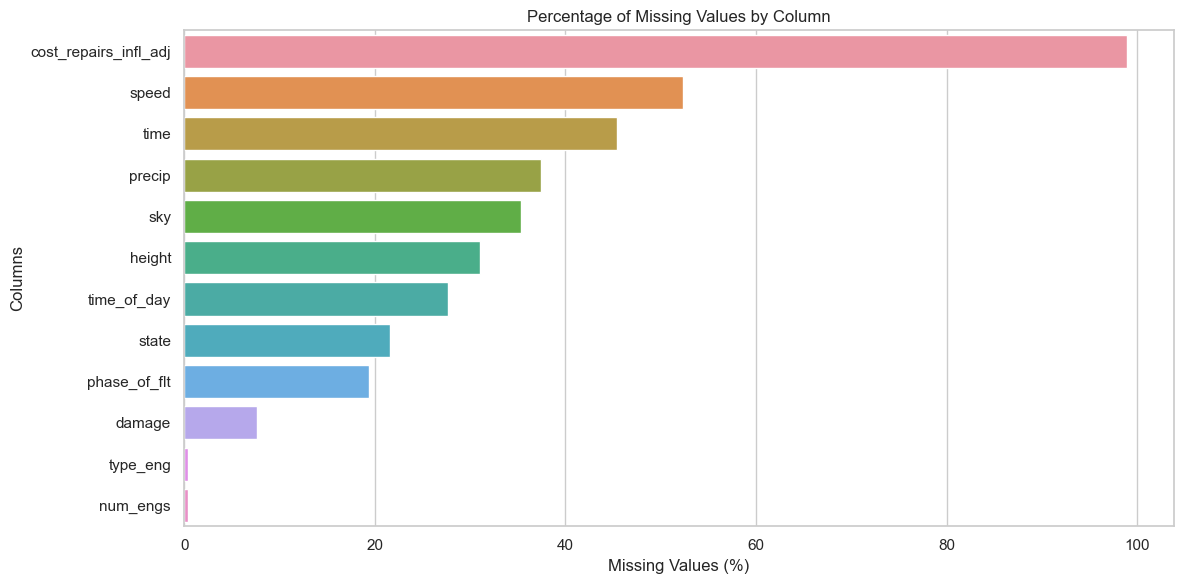

In [162]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_percentage = missing_percentage[missing_percentage > 0]
missing_percentage = missing_percentage.sort_values(ascending=False)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=missing_percentage.values,
    y=missing_percentage.index
)

plt.title("Percentage of Missing Values by Column")
plt.xlabel("Missing Values (%)")
plt.ylabel("Columns")
plt.tight_layout()
plt.show()

### Distribution of Numerical Columns with Missing Values


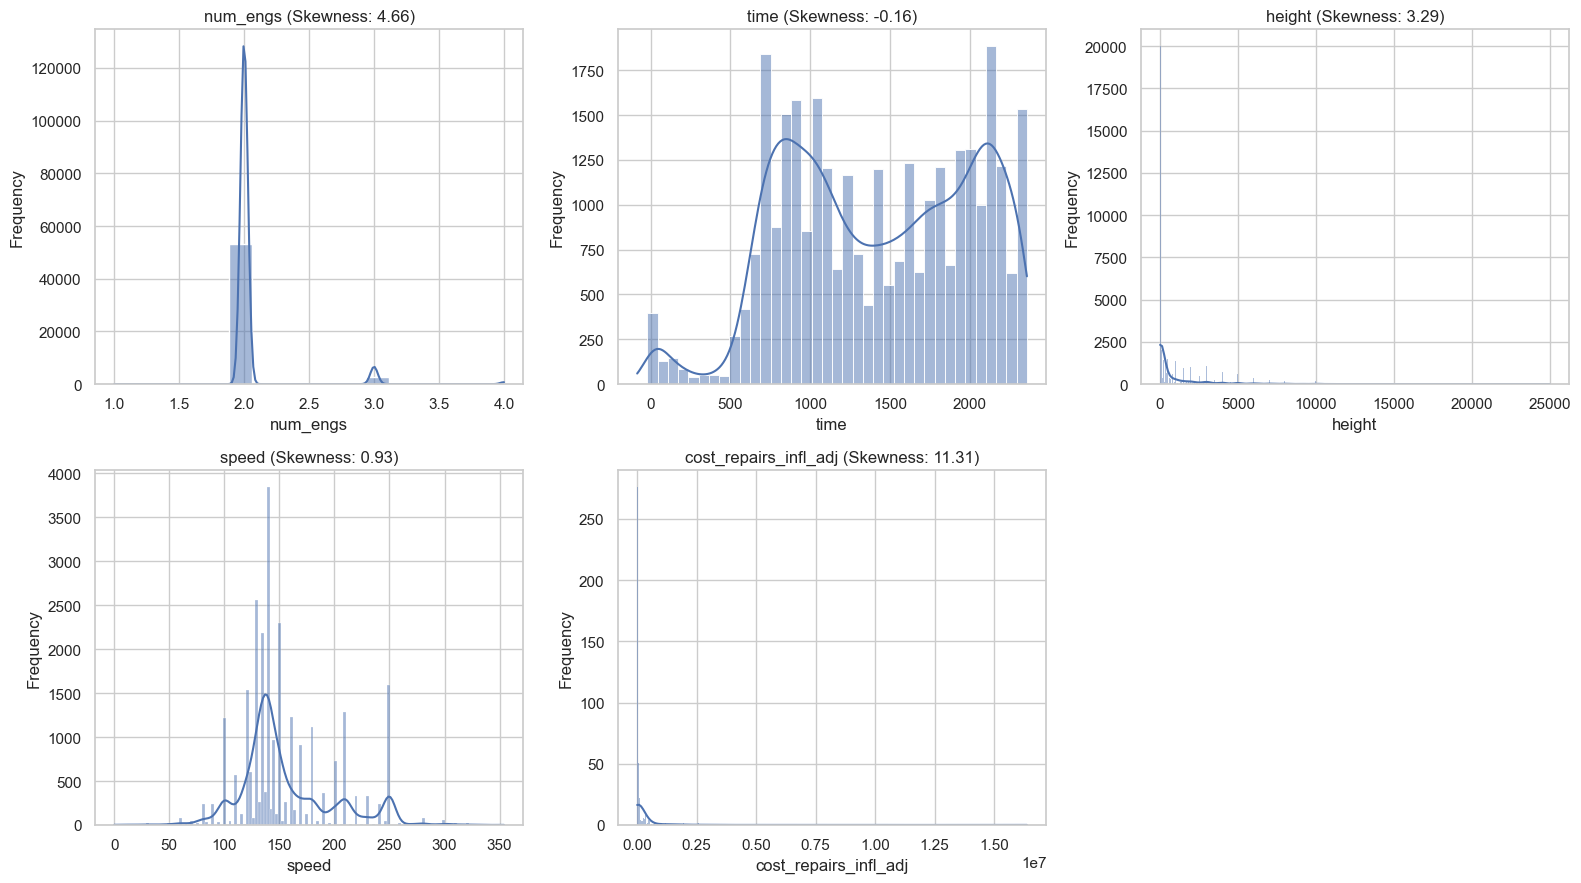

In [163]:
numerical_columns = ['num_engs', 'time', 'height', 'speed', 'cost_repairs_infl_adj']

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, col in enumerate(numerical_columns):
    sns.histplot(df[col].dropna(), kde=True, ax=axes[i])
    skewness = df[col].skew()
    axes[i].set_title(f'{col} (Skewness: {skewness:.2f})')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Frequency')

for i in range(len(numerical_columns), len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.show()

### Handling Missing Values in Numerical Columns

The `num_engs`, `height`, and `speed` columns are imputed with their medians because these variables may be skewed and can contain extreme observations. The `time` column uses HHMM-style clock values, so taking a numeric mean can create misleading times; missing times are therefore retained as missing rather than fabricated. Analyses using `time` should handle missing values explicitly. The repair-cost column is investigated separately because it contains a very high percentage of missing values.

In [220]:

df['num_engs'] = df['num_engs'].fillna(df['num_engs'].median())
df['height'] = df['height'].fillna(df['height'].median())
df['speed'] = df['speed'].fillna(df['speed'].median())
print('Missing time values retained for transparent analysis:', df['time'].isna().sum())

Missing time values retained for transparent analysis: 9752


### Investigating Missing Time Values by Flight Phase

In [226]:
# Separate records with missing and available time values
missing_time = df[df['time'].isna()]
available_time = df[df['time'].notna()]

# Compare missing-time counts by flight phase
print("Missing time values by flight phase:")
print(missing_time['phase_of_flt'].value_counts().head(15))

print("\nAvailable time values by flight phase:")
print(available_time['phase_of_flt'].value_counts().head(15))

# Calculate the percentage of missing times by flight phase
time_missing_rate = (
    df.assign(time_missing=df['time'].isna())
      .groupby('phase_of_flt')['time_missing']
      .mean()
      .mul(100)
      .sort_values(ascending=False)
)

print("\nPercentage of missing times by flight phase:")
print(time_missing_rate.round(2).head(15))

Missing time values by flight phase:
Unknown    9752
Name: phase_of_flt, dtype: int64

Available time values by flight phase:
Approach        20642
Take-Off Run     8264
Climb            7672
Landing Roll     7278
Unknown          1235
Descent           661
Departure         470
Arrival           190
Local             116
En Route           81
Taxi               76
Parked             12
Name: phase_of_flt, dtype: int64

Percentage of missing times by flight phase:
phase_of_flt
Unknown         88.76
Approach         0.00
Arrival          0.00
Climb            0.00
Departure        0.00
Descent          0.00
En Route         0.00
Landing Roll     0.00
Local            0.00
Parked           0.00
Take-Off Run     0.00
Taxi             0.00
Name: time_missing, dtype: float64


### Investigating Time Imputation by Airport and Flight Phase

Missing time values will be investigated using airport and flight phase. Group-based imputation will be considered only when a group has enough valid observations. Original observed times will be preserved.

In [166]:
# Check how many valid time observations exist in each group
group_time_stats = (
    df[df['time'].notna()]
    .groupby(['airport', 'phase_of_flt'])['time']
    .agg(['count', 'median'])
    .reset_index()
)

print("Groups with at least 20 observed times:")
print(
    group_time_stats[group_time_stats['count'] >= 20]
    .sort_values('count', ascending=False)
    .head(20)
)

# Check how many missing-time records belong to groups with enough observations
missing_time = df[df['time'].isna()]

missing_time_groups = missing_time.merge(
    group_time_stats,
    on=['airport', 'phase_of_flt'],
    how='left'
)

print("\nMissing-time records:", len(missing_time))
print(
    "Records in groups with at least 20 observed times:",
    (missing_time_groups['count'] >= 20).sum()
)
print(
    "Records without enough group observations:",
    (missing_time_groups['count'].fillna(0) < 20).sum()
)

Groups with at least 20 observed times:
                                        airport  phase_of_flt  count  median
290                 DALLAS/FORT WORTH INTL ARPT      Approach    604  1416.5
1180                            SACRAMENTO INTL      Approach    580  1842.5
329                         DENVER INTL AIRPORT  Landing Roll    473  1001.0
295                 DALLAS/FORT WORTH INTL ARPT  Landing Roll    424  1246.5
1194                        SALT LAKE CITY INTL      Approach    413  1800.0
55    BALTIMORE/WASH INTL THURGOOD MARSHAL ARPT      Approach    413  1645.0
698                             LA GUARDIA ARPT      Approach    388  2054.5
535      HARTSFIELD - JACKSON ATLANTA INTL ARPT      Approach    373  1640.0
211                    CHICAGO MIDWAY INTL ARPT      Approach    361  1554.0
941                    NEWARK LIBERTY INTL ARPT      Approach    342  1951.5
333                         DENVER INTL AIRPORT  Take-off run    330  1036.0
44                        AUSTIN-BER

### Imputing Missing Time Values Using Airport and Flight Phase

Missing time values are estimated using the median time for the corresponding airport and flight phase. HHMM values are first converted into minutes after midnight to make the median calculation meaningful. Only groups with at least 20 valid observations are used, and original observed times are preserved. Records without sufficient group data remain missing.

In [167]:
import numpy as np
import pandas as pd

# Convert valid HHMM values into minutes after midnight
def hhmm_to_minutes(value):
    if pd.isna(value):
        return np.nan

    value = int(value)
    hour = value // 100
    minute = value % 100

    if hour > 23 or minute > 59 or value < 0:
        return np.nan

    return hour * 60 + minute


# Convert time values to minutes
time_minutes = df['time'].apply(hhmm_to_minutes)

# Calculate group medians using valid time observations
valid_time = df.loc[time_minutes.notna()].copy()
valid_time['time_minutes'] = time_minutes[time_minutes.notna()]

group_medians = (
    valid_time.groupby(['airport', 'phase_of_flt'])['time_minutes']
    .agg(['median', 'count'])
    .reset_index()
)

# Keep groups with at least 20 valid observations
group_medians = group_medians[group_medians['count'] >= 20]

# Identify rows with missing time values
missing_time_mask = df['time'].isna()

# Match missing records to their airport and flight phase
missing_records = df.loc[
    missing_time_mask, ['airport', 'phase_of_flt']
].copy()

missing_records['_row_index'] = missing_records.index

missing_records = missing_records.merge(
    group_medians,
    on=['airport', 'phase_of_flt'],
    how='left'
).set_index('_row_index')

# Impute only records with an available group median
imputable_indices = missing_records.index[
    missing_records['median'].notna()
]

# Convert median minutes back into HHMM format
estimated_minutes = missing_records.loc[imputable_indices, 'median'].round().astype(int)

estimated_hhmm = (
    (estimated_minutes // 60) * 100
    + (estimated_minutes % 60)
)

df.loc[imputable_indices, 'time'] = estimated_hhmm

# Verify the results
print("Time values imputed:", len(imputable_indices))
print("Missing time values remaining:", df['time'].isna().sum())

Time values imputed: 12698
Missing time values remaining: 12909


### Verifying Time Imputation Results

Missing time values were imputed using the median time for the corresponding airport and flight phase, provided that the group contained at least 20 valid observations. The original observed times were preserved. A total of 3,498 values remain missing because there were insufficient observations for reliable group-based imputation.

In [168]:
# Verify missing values after imputation
print("Missing time values:", df['time'].isna().sum())

print("\nTime data type:")
print(df['time'].dtype)

print("\nSample of updated time values:")
print(df['time'].dropna().head(10))

Missing time values: 12909

Time data type:
float64

Sample of updated time values:
0     1207.0
1     2355.0
5      955.0
6      948.0
9     1321.0
10      15.0
11    1612.0
14     905.0
15    1457.0
16    1418.0
Name: time, dtype: float64


### Imputing Remaining Missing Time Values Using Flight Phase

The remaining missing time values are imputed using the median time for the corresponding flight phase. This fallback method is used because some airport-and-flight-phase groups did not have enough observations. Time values are converted to minutes after midnight before calculating medians to avoid misleading calculations with HHMM values. Any values that cannot be estimated from the flight phase remain missing.

In [169]:
# Calculate the median time in minutes for each flight phase
valid_time_mask = df['time'].apply(
    lambda x: pd.notna(x) and hhmm_to_minutes(x) == hhmm_to_minutes(x)
)

phase_data = df.loc[valid_time_mask, ['phase_of_flt', 'time']].copy()

phase_data['time_minutes'] = phase_data['time'].apply(hhmm_to_minutes)

phase_medians = (
    phase_data.groupby('phase_of_flt')['time_minutes']
    .median()
)

# Fill only the remaining missing time values
remaining_missing = df['time'].isna()

for idx in df.index[remaining_missing]:
    phase = df.at[idx, 'phase_of_flt']

    if phase in phase_medians.index and pd.notna(phase_medians[phase]):
        minutes = int(round(phase_medians[phase]))
        df.at[idx, 'time'] = (minutes // 60) * 100 + (minutes % 60)

# Verify results
print("Time values still missing:", df['time'].isna().sum())
print("Total time values now available:", df['time'].notna().sum())

Time values still missing: 9752
Total time values now available: 46697


In [228]:
# Examine the flight phases of records with missing times
print(
    df.loc[df['time'].isna(), 'phase_of_flt']
      .value_counts(dropna=False)
)

Unknown    9752
Name: phase_of_flt, dtype: int64


### Investigating Time Availability by Flight Phase

The availability of valid time observations is examined for each flight phase. This helps determine whether further imputation of missing times is justified.


In [229]:
# Convert valid HHMM times to minutes after midnight
valid_mask = df['time'].apply(
    lambda x: pd.notna(x) and pd.notna(hhmm_to_minutes(x))
)

time_analysis = df.loc[valid_mask].groupby('phase_of_flt').agg(
    valid_time_count=('time', 'count'),
    median_time=('time', 'median')
).sort_values('valid_time_count', ascending=False)

print(time_analysis)

              valid_time_count  median_time
phase_of_flt                               
Approach                 20642       1715.0
Take-Off Run              8263       1055.0
Climb                     7672       1300.0
Landing Roll              7277       1258.0
Unknown                   1235       1300.0
Descent                    661       2100.0
Departure                  470       1130.0
Arrival                    190       1255.0
Local                      116       1215.0
En Route                    80       1432.0
Taxi                        76       1238.0
Parked                      12       1015.0


### Imputing Remaining Missing Time Values

The remaining missing time values belong to records with an unknown flight phase. The median time of valid observations within this group is used to estimate the missing values. This approach assumes that the observed times are reasonably representative of the missing records, so the imputed values should be interpreted as estimates rather than actual incident times.


In [230]:
# Calculate the median time in minutes for the Unknown flight phase
unknown_times = df.loc[
    (df['phase_of_flt'] == 'Unknown') & df['time'].notna(),
    'time'
].apply(hhmm_to_minutes).dropna()

unknown_phase_median = unknown_times.median()

print("Unknown phase median (minutes):", unknown_phase_median)

# Fill missing times only for the Unknown flight phase
mask = (
    (df['phase_of_flt'] == 'Unknown') &
    df['time'].isna()
)

minutes = int(round(unknown_phase_median))

estimated_hhmm = (minutes // 60) * 100 + (minutes % 60)

df.loc[mask, 'time'] = estimated_hhmm

print("Time values imputed:", mask.sum())
print("Missing time values remaining:", df['time'].isna().sum())

Unknown phase median (minutes): 780.0
Time values imputed: 9752
Missing time values remaining: 0


### Investigating Unresolved Missing Time Values

The remaining missing time values are examined by flight phase to determine whether any additional reliable imputation is possible. Values that cannot be estimated reliably will remain missing to preserve data integrity.


### Dropping Column with Excessive Missing Values

The `cost_repairs_infl_adj` column contains approximately 98% missing values. Since it provides insufficient data for reliable analysis and is not required for our project, we remove it from the dataset.


In [170]:
df.drop(columns=['cost_repairs_infl_adj'], inplace=True)

### Identifying Categorical Columns with Missing Values


In [171]:
print(df.select_dtypes(include='object').isnull().sum())

incident_date        0
state            12168
airport_id           0
airport              0
operator             0
atype                0
type_eng           232
species_id           0
species              0
damage            4317
time_of_day      15619
phase_of_flt     10964
sky              19976
precip           21103
dtype: int64


###  Investigating Relationships Between Categorical Columns

In [172]:
print("State vs Airport ID")
print(pd.crosstab(df['state'], df['airport_id']).head(10))

print("\nAircraft Type vs Aircraft Description")
print(pd.crosstab(df['atype'], df['type_eng']).head(10))

print("\nTime of Day vs Time")
print(df.groupby('time_of_day', dropna=False)['time'].agg(['count', 'min', 'max']))

print("\nDamage vs Flight Phase")
print(pd.crosstab(df['damage'], df['phase_of_flt'], dropna=False))

State vs Airport ID
airport_id  28NJ  33N  3FD1  9G0  CYEG  CYOW  CYUL  CYVR  CYYC  CYYZ  ...  \
state                                                                 ...   
AB             0    0     0    0     2     0     0     0    16     0  ...   
AK             0    0     0    0     0     0     0     0     0     0  ...   
AL             0    0     0    0     0     0     0     0     0     0  ...   
AR             0    0     0    0     0     0     0     0     0     0  ...   
AZ             0    0     0    0     0     0     0     0     0     0  ...   
BC             0    0     0    0     0     0     0    53     0     0  ...   
CA             0    0     0    0     0     0     0     0     0     0  ...   
CO             0    0     0    0     0     0     0     0     0     0  ...   
CT             0    0     0    0     0     0     0     0     0     0  ...   
DC             0    0     0    0     0     0     0     0     0     0  ...   

airport_id  PHLI  PHNL  PHOG  PHTO  PKMJ  PMDY  TIST  T

###  Checking Whether Airport IDs Consistently Map to States

In [173]:
airport_mapping = (
    df.dropna(subset=['airport_id', 'state'])
      .groupby('airport_id')['state']
      .nunique()
)

print("Airport IDs with only one associated state:",
      (airport_mapping == 1).sum())

print("Airport IDs associated with multiple states:",
      (airport_mapping > 1).sum())

print("\nExamples of airport IDs associated with multiple states:")
print(airport_mapping[airport_mapping > 1].head(10))

Airport IDs with only one associated state: 285
Airport IDs associated with multiple states: 0

Examples of airport IDs associated with multiple states:
Series([], Name: state, dtype: int64)


###  Filling Missing State Values Using Airport ID

In [174]:
# Create a reliable airport ID-to-state mapping
airport_state_map = (
    df.dropna(subset=['airport_id', 'state'])
      .drop_duplicates('airport_id')
      .set_index('airport_id')['state']
)

# Fill missing state values using the mapping
missing_state = df['state'].isna()

df.loc[missing_state, 'state'] = (
    df.loc[missing_state, 'airport_id'].map(airport_state_map)
)

print("Missing state values after mapping:", df['state'].isna().sum())

Missing state values after mapping: 12168


### 1.3 Filling Remaining Missing State Values

In [175]:
# Fill states that cannot be determined from airport ID
df['state'] = df['state'].fillna('Unknown')

print("Remaining missing state values:", df['state'].isna().sum())
print("\nState value counts:")
print(df['state'].value_counts().head(10))

Remaining missing state values: 0

State value counts:
Unknown    12168
TX          7143
CA          5779
FL          3685
IL          2739
CO          2435
NY          2241
MO          1674
TN          1251
DC          1226
Name: state, dtype: int64


###  Investigating the Relationship Between Aircraft Type and Aircraft Description

In [176]:
# Check whether each aircraft type has a consistent description

aircraft_mapping = (
    df.dropna(subset=['atype', 'type_eng'])
      .groupby('atype')['type_eng']
      .agg(['nunique', 'first'])
)

print("Aircraft types with multiple descriptions:")
print(aircraft_mapping[aircraft_mapping['nunique'] > 1])

print("\nAircraft type-to-description mapping:")
print(aircraft_mapping.head(20))

print("\nMissing values before filling:")
print(df[['atype', 'type_eng']].isna().sum())

Aircraft types with multiple descriptions:
Empty DataFrame
Columns: [nunique, first]
Index: []

Aircraft type-to-description mapping:
           nunique first
atype                   
A-300            1     D
A-310            1     D
A-318            1     D
A-319            1     D
A-320            1     D
A-321            1     D
A-330            1     D
A-340            1     D
AIRBUS           1     D
ATR-42           1     C
ATR-72           1     C
B-707            1     D
B-717            1     D
B-717-200        1     D
B-727            1     D
B-727-100        1     D
B-727-200        1     D
B-737            1     D
B-737-100        1     D
B-737-200        1     D

Missing values before filling:
atype         0
type_eng    232
dtype: int64


### Filling Missing Aircraft Engine-Type Descriptions

In [177]:
# Create a mapping between aircraft type and engine description
aircraft_map = (
    df.dropna(subset=['type_eng'])
      .drop_duplicates('atype')
      .set_index('atype')['type_eng']
)

# Fill missing type_eng values using atype
missing_type_eng = df['type_eng'].isna()

df.loc[missing_type_eng, 'type_eng'] = (
    df.loc[missing_type_eng, 'atype'].map(aircraft_map)
)

# Fill any remaining missing values with Unknown
df['type_eng'] = df['type_eng'].fillna('Unknown')

print("Remaining missing type_eng values:", df['type_eng'].isna().sum())
print("\nNumber of Unknown values:", (df['type_eng'] == 'Unknown').sum())
print("\nUpdated type_eng value counts:")
print(df['type_eng'].value_counts())

Remaining missing type_eng values: 0

Number of Unknown values: 232

Updated type_eng value counts:
D          56178
Unknown      232
C             34
F              3
A              2
Name: type_eng, dtype: int64


### Handling Missing Values in the Damage Column

In [178]:
# Check the distribution of damage values
print("Missing values in damage:", df['damage'].isna().sum())

print("\nDamage value counts:")
print(df['damage'].value_counts(dropna=False))

print("\nDamage values by aircraft type:")
print(pd.crosstab(df['atype'], df['damage'], dropna=False).head(15))

Missing values in damage: 4317

Damage value counts:
N      48133
NaN     4317
M       1888
M?      1085
S       1026
Name: damage, dtype: int64

Damage values by aircraft type:
damage       M  M?     N   S
atype                       
A-300        8   6   174  17
A-310        0   0    10   1
A-318        0   0     8   0
A-319       79  59  2551  30
A-320      143  53  3099  36
A-321       16  43  1138   3
A-330        6   5    67   3
A-340        0   0     1   0
AIRBUS       0   0     1   0
ATR-42       0   0     2   0
ATR-72       0   0     2   0
B-717-200    2   7   417   1
B-727       20  10   662   6
B-727-100    5   1    76   0
B-727-200   75  18  1312  15


### Investigating Missing Damage Values

In [179]:
# Examine other categorical columns for records with missing damage
missing_damage = df[df['damage'].isna()]

print("Missing damage records:", len(missing_damage))

print("\nMissing damage by phase of flight:")
print(missing_damage['phase_of_flt'].value_counts(dropna=False).head(15))

print("\nMissing damage by sky condition:")
print(missing_damage['sky'].value_counts(dropna=False))

print("\nMissing damage by precipitation:")
print(missing_damage['precip'].value_counts(dropna=False))

print("\nMissing damage by aircraft type:")
print(missing_damage['atype'].value_counts().head(15))

Missing damage records: 4317

Missing damage by phase of flight:
Take-off run    1297
Approach         840
NaN              715
Landing Roll     636
Climb            548
Departure        140
Arrival           53
Local             34
Taxi              13
Descent           12
Take-off Run       8
En Route           6
Landing roll       5
take-off run       5
landing roll       2
Name: phase_of_flt, dtype: int64

Missing damage by sky condition:
NaN           2145
No Cloud       853
Some Cloud     852
Overcast       467
Name: sky, dtype: int64

Missing damage by precipitation:
NaN           2240
None          1856
Rain           152
Fog             53
Snow            12
Fog, Rain        3
Rain, Snow       1
Name: precip, dtype: int64

Missing damage by aircraft type:
B-737-700    527
B-737-800    414
A-320        354
B-757-200    329
A-319        299
B-737        274
B-737-300    264
MD-88        221
MD-80        184
A-321        139
B-737-900    138
UNKNOWN      117
MD-82        102
B-73

### Handling Missing Values in the Damage Column

In [180]:
# Replace missing damage values with Unknown
df['damage'] = df['damage'].fillna('Unknown')

# Verify the result
print("Remaining missing damage values:", df['damage'].isna().sum())

print("\nUpdated damage value counts:")
print(df['damage'].value_counts())

Remaining missing damage values: 0

Updated damage value counts:
N          48133
Unknown     4317
M           1888
M?          1085
S           1026
Name: damage, dtype: int64


### Investigating Missing Values in Time of Day

In [181]:
# Check missing values in time_of_day and time
print("Missing values in time_of_day:", df['time_of_day'].isna().sum())
print("Missing values in time:", df['time'].isna().sum())

print("\nTime of day value counts:")
print(df['time_of_day'].value_counts(dropna=False))

print("\nExamples of time values:")
print(df['time'].dropna().head(20))

print("\nTime format and data type:")
print(df['time'].dtype)

Missing values in time_of_day: 15619
Missing values in time: 9752

Time of day value counts:
Day      25113
NaN      15619
Night    12731
Dusk      1717
Dawn      1269
Name: time_of_day, dtype: int64

Examples of time values:
0     1207.0
1     2355.0
5      955.0
6      948.0
9     1321.0
10      15.0
11    1612.0
14     905.0
15    1457.0
16    1418.0
17    1628.0
18     627.0
19    2130.0
20     719.0
21     747.0
24    1348.0
27    1305.0
32    1345.0
33     944.0
34    1400.0
Name: time, dtype: float64

Time format and data type:
float64


### Investigating the Relationship Between Time and Time of Day

In [182]:
# Examine time values for each existing time_of_day category
for category in df['time_of_day'].dropna().unique():
    print(f"\n{category}:")
    print(
        df.loc[df['time_of_day'] == category, 'time']
        .dropna()
        .describe()
    )

# Display sample records with both values available
print("\nSample records with known time and time_of_day:")
print(
    df.loc[
        df['time_of_day'].notna() & df['time'].notna(),
        ['time', 'time_of_day']
    ].sample(15, random_state=42)
)


Day:
count    24716.000000
mean      1257.171549
std        376.690478
min        -84.000000
25%        945.000000
50%       1230.000000
75%       1550.000000
max       2347.000000
Name: time, dtype: float64

Night:
count    12438.000000
mean      1828.336951
std        576.502149
min          0.000000
25%       1715.000000
50%       2040.000000
75%       2200.000000
max       2359.000000
Name: time, dtype: float64

Dawn:
count    1251.000000
mean      884.223821
std       360.965988
min         7.000000
25%       630.000000
50%       710.000000
75%      1100.000000
max      2146.000000
Name: time, dtype: float64

Dusk:
count    1703.000000
mean     1708.731063
std       340.247006
min         0.000000
25%      1600.000000
50%      1816.000000
75%      1937.500000
max      2350.000000
Name: time, dtype: float64

Sample records with known time and time_of_day:
         time time_of_day
757     223.0       Night
34544  2150.0       Night
36302  1645.0       Night
13427  2054.0       Nig

### Filling Missing Values in Time of Day

In [183]:
# Convert numeric time values into HHMM format
def get_time_of_day(value):
    if pd.isna(value):
        return 'Unknown'

    value = int(value)

    if value < 0 or value > 2359:
        return 'Unknown'

    hour = value // 100
    minute = value % 100

    if hour > 23 or minute > 59:
        return 'Unknown'

    total_minutes = hour * 60 + minute

    # Use approximate time boundaries
    if total_minutes < 360:
        return 'Night'       # Before 6:00 AM
    elif total_minutes < 420:
        return 'Dawn'        # 6:00–6:59 AM
    elif total_minutes < 1020:
        return 'Day'         # 7:00 AM–4:59 PM
    elif total_minutes < 1140:
        return 'Dusk'        # 5:00–6:59 PM
    else:
        return 'Night'       # 7:00 PM onward


# Fill only missing time_of_day values where time is available
missing_tod = df['time_of_day'].isna() & df['time'].notna()

df.loc[missing_tod, 'time_of_day'] = (
    df.loc[missing_tod, 'time'].apply(get_time_of_day)
)

# Fill any remaining missing values with Unknown
df['time_of_day'] = df['time_of_day'].fillna('Unknown')

print("Remaining missing time_of_day values:", df['time_of_day'].isna().sum())
print("\nUpdated time_of_day value counts:")
print(df['time_of_day'].value_counts())

Remaining missing time_of_day values: 0

Updated time_of_day value counts:
Day        29956
Night      13563
Unknown     9030
Dusk        2597
Dawn        1303
Name: time_of_day, dtype: int64


### Handling Missing Values in Flight Phase

In [184]:
# Check missing values in phase_of_flt
print("Missing values in phase_of_flt:", df['phase_of_flt'].isna().sum())

print("\nFlight phase value counts:")
print(df['phase_of_flt'].value_counts(dropna=False))

print("\nFlight phase by aircraft type:")
print(pd.crosstab(df['atype'], df['phase_of_flt'], dropna=False).head(15))

Missing values in phase_of_flt: 10964

Flight phase value counts:
Approach        20592
NaN             10964
Take-off run     8226
Climb            7656
Landing Roll     7240
Descent           661
Departure         447
Arrival           179
Local             116
En Route           81
Taxi               76
APPROACH           42
Unknown            23
DEPARTURE          23
Landing roll       16
LANDING ROLL       15
TAKE-OFF RUN       15
Take-off Run       14
CLIMB              13
Parked             12
ARRIVAL            11
take-off run        9
approach            8
landing roll        7
climb               3
Name: phase_of_flt, dtype: int64

Flight phase by aircraft type:
phase_of_flt  APPROACH  ARRIVAL  Approach  Arrival  CLIMB  Climb  DEPARTURE  \
atype                                                                         
A-300                0        0        71        0      0     43          0   
A-310                0        0         4        0      0      3          0   
A-3

### Standardizing Flight Phase Categories

In [185]:
# Standardize capitalization and remove extra spaces
df['phase_of_flt'] = df['phase_of_flt'].apply(
    lambda x: x.strip().title() if isinstance(x, str) else x
)

# Check the updated categories
print("Missing values:", df['phase_of_flt'].isna().sum())

print("\nUpdated flight phase categories:")
print(df['phase_of_flt'].value_counts(dropna=False))

Missing values: 10964

Updated flight phase categories:
Approach        20642
NaN             10964
Take-Off Run     8264
Climb            7672
Landing Roll     7278
Descent           661
Departure         470
Arrival           190
Local             116
En Route           81
Taxi               76
Unknown            23
Parked             12
Name: phase_of_flt, dtype: int64


### Handling Missing Values in Flight Phase

In [186]:
# Fill missing flight phases with Unknown
df['phase_of_flt'] = df['phase_of_flt'].fillna('Unknown')

# Verify the result
print("Remaining missing values:", df['phase_of_flt'].isna().sum())

print("\nUpdated flight phase categories:")
print(df['phase_of_flt'].value_counts())

Remaining missing values: 0

Updated flight phase categories:
Approach        20642
Unknown         10987
Take-Off Run     8264
Climb            7672
Landing Roll     7278
Descent           661
Departure         470
Arrival           190
Local             116
En Route           81
Taxi               76
Parked             12
Name: phase_of_flt, dtype: int64


### Investigating Missing Values in Sky Condition

In [187]:
# Check missing values in sky
print("Missing values in sky:", df['sky'].isna().sum())

print("\nSky condition value counts:")
print(df['sky'].value_counts(dropna=False))

print("\nSky condition by time of day:")
print(pd.crosstab(df['time_of_day'], df['sky'], dropna=False))

print("\nSky condition by flight phase:")
print(pd.crosstab(df['phase_of_flt'], df['sky'], dropna=False).head(15))

Missing values in sky: 19976

Sky condition value counts:
NaN           19976
No Cloud      18926
Some Cloud    12102
Overcast       5445
Name: sky, dtype: int64

Sky condition by time of day:
sky          No Cloud  Overcast  Some Cloud
time_of_day                                
Dawn              534       283         299
Day             10385      3673        7520
Dusk              782       235         676
Night            6771      1190        3302
Unknown           454        64         305

Sky condition by flight phase:
sky           No Cloud  Overcast  Some Cloud
phase_of_flt                                
Approach          9288      2242        5198
Arrival             16         7          17
Climb             3269       834        1901
Departure           20         9          27
Descent            334        38         164
En Route            31         4          12
Landing Roll      2290      1036        2007
Local               28        16          22
Parked           

### Handling Missing Values in Sky Condition

In [188]:
# Fill missing sky conditions with Unknown
df['sky'] = df['sky'].fillna('Unknown')

# Verify the result
print("Remaining missing values:", df['sky'].isna().sum())

print("\nUpdated sky condition value counts:")
print(df['sky'].value_counts())

Remaining missing values: 0

Updated sky condition value counts:
Unknown       19976
No Cloud      18926
Some Cloud    12102
Overcast       5445
Name: sky, dtype: int64


### Investigating Missing Values in Precipitation

In [189]:
# Check missing values in precip
print("Missing values in precip:", df['precip'].isna().sum())

print("\nPrecipitation value counts:")
print(df['precip'].value_counts(dropna=False))

print("\nPrecipitation by sky condition:")
print(pd.crosstab(df['sky'], df['precip'], dropna=False))

print("\nPrecipitation by time of day:")
print(pd.crosstab(df['time_of_day'], df['precip'], dropna=False))

Missing values in precip: 21103

Precipitation value counts:
None          32922
NaN           21103
Rain           1686
Fog             587
Snow             85
Fog, Rain        58
Fog, Snow         5
Rain, Snow        3
Name: precip, dtype: int64

Precipitation by sky condition:
precip      Fog  Fog, Rain  Fog, Snow   None  Rain  Rain, Snow  Snow
sky                                                                 
No Cloud     35          0          0  18275    18           0     2
Overcast    435         53          5   3232  1348           3    73
Some Cloud  102          5          0  11158   297           0    10
Unknown      15          0          0    257    23           0     0

Precipitation by time of day:
precip       Fog  Fog, Rain  Fog, Snow   None  Rain  Rain, Snow  Snow
time_of_day                                                          
Dawn          79          8          0    919    67           0     3
Day          369         35          1  19356  1082           2 

### Handling Missing Values in Precipitation

In [190]:
# Fill missing precipitation values with Unknown
df['precip'] = df['precip'].fillna('Unknown')

# Verify the result
print("Remaining missing values:", df['precip'].isna().sum())

print("\nUpdated precipitation value counts:")
print(df['precip'].value_counts())

Remaining missing values: 0

Updated precipitation value counts:
None          32922
Unknown       21103
Rain           1686
Fog             587
Snow             85
Fog, Rain        58
Fog, Snow         5
Rain, Snow        3
Name: precip, dtype: int64


In [191]:
# Identify categorical columns
categorical_columns = df.select_dtypes(
    include=['object', 'category']
).columns

# Check missing values in categorical columns
missing_categorical = df[categorical_columns].isna().sum()

print("Missing values in each categorical column:")
print(missing_categorical)

print("\nTotal missing values in categorical columns:",
      missing_categorical.sum())

print("\nCategorical columns with missing values:")
print(missing_categorical[missing_categorical > 0])

Missing values in each categorical column:
incident_date    0
state            0
airport_id       0
airport          0
operator         0
atype            0
type_eng         0
species_id       0
species          0
damage           0
time_of_day      0
phase_of_flt     0
sky              0
precip           0
dtype: int64

Total missing values in categorical columns: 0

Categorical columns with missing values:
Series([], dtype: int64)


### Converting Incident Date to Datetime
The incident_date column is converted to datetime format to support time-based analysis and visualization.

In [222]:
df['incident_date'] = pd.to_datetime(df['incident_date'], errors='coerce')

print("Data type:", df['incident_date'].dtype)
print("Missing dates:", df['incident_date'].isna().sum())
print(df['incident_date'].head())

Data type: datetime64[ns, UTC]
Missing dates: 0
0   2018-12-31 00:00:00+00:00
1   2018-12-29 00:00:00+00:00
2   2018-12-29 00:00:00+00:00
3   2018-12-27 00:00:00+00:00
4   2018-12-27 00:00:00+00:00
Name: incident_date, dtype: datetime64[ns, UTC]


### Final Data Cleaning Verification


In [234]:
print("Dataset Shape:", df.shape)


print("\nTotal Missing Values:", df.isnull().sum().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nData Types:")
print(df.dtypes)

print("\nFinal Verification Completed!")

Dataset Shape: (56441, 23)

Total Missing Values: 0

Duplicate Rows: 0

Data Types:
incident_date      datetime64[ns, UTC]
state                           object
airport_id                      object
airport                         object
operator                        object
atype                           object
type_eng                        object
species_id                      object
species                         object
damage                          object
num_engs                       float64
incident_month                   int64
incident_year                    int64
time_of_day                     object
time                           float64
height                         float64
speed                          float64
phase_of_flt                    object
sky                             object
precip                          object
season                          object
height_category               category
year_group                    category
dtype: object

Fina

## Univariate Analysis

## Question 1: How Have Wildlife Incidents Changed Over Time?


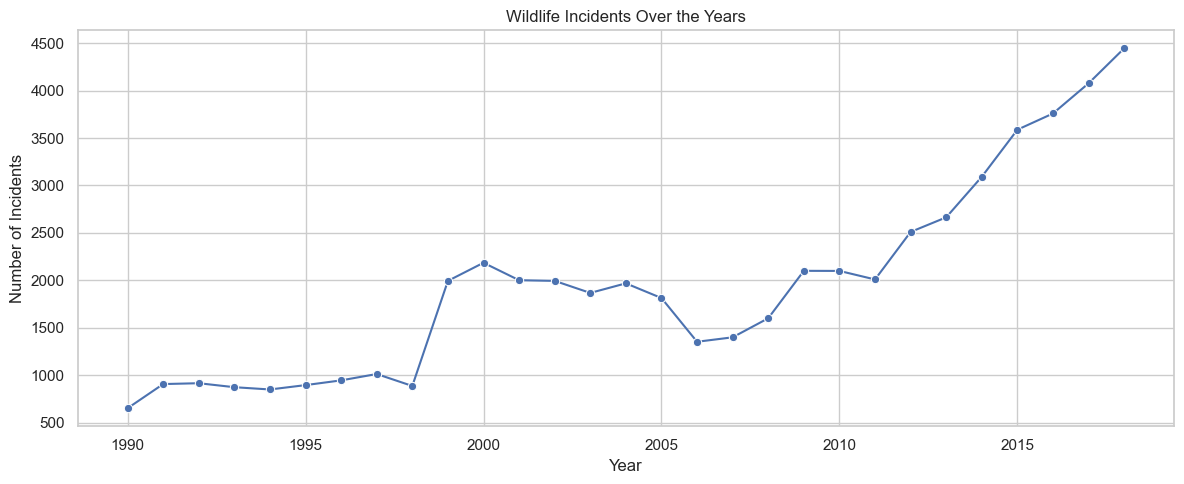

In [193]:
yearly_incidents = df['incident_year'].value_counts().sort_index()

plt.figure(figsize=(12, 5))
sns.lineplot(x=yearly_incidents.index, y=yearly_incidents.values, marker='o')

plt.title('Wildlife Incidents Over the Years')
plt.xlabel('Year')
plt.ylabel('Number of Incidents')
plt.tight_layout()
plt.show()

### Interpretation

The line chart shows an overall increase in reported wildlife incidents between 1990 and 2018.

- **1990–1998:** The number of incidents remained relatively low, generally below 1,000 per year.
- **1999–2005:** A sharp increase occurred in 1999, followed by fluctuations in the number of incidents.
- **2006–2008:** The number of incidents declined and then began to recover.
- **2009–2011:** Incident counts fluctuated moderately.
- **2012–2018:** A substantial increase occurred, with the highest number of incidents recorded in 2018.

## Question 2: During which months do the most wildlife incidents occur?

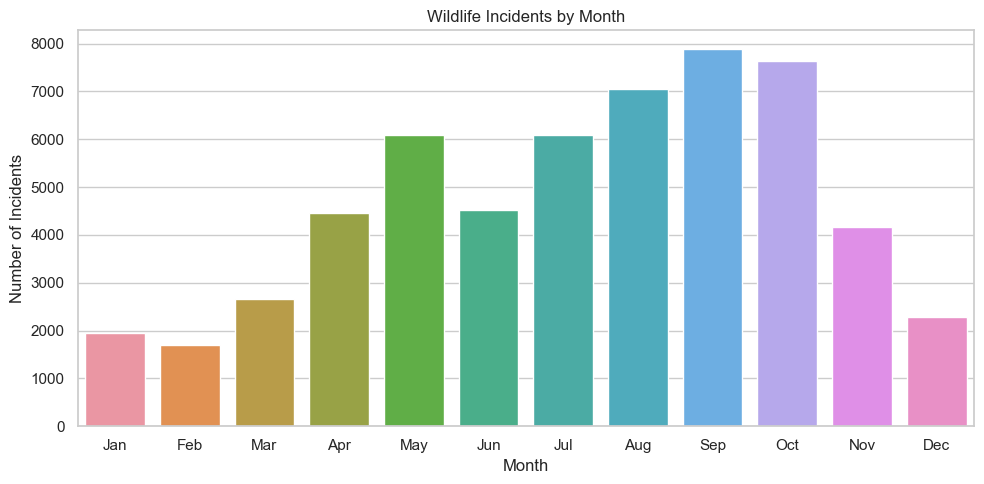

In [194]:
monthly_incidents = df['incident_month'].value_counts().sort_index()

plt.figure(figsize=(10, 5))
sns.barplot(x=monthly_incidents.index, y=monthly_incidents.values)

plt.title('Wildlife Incidents by Month')
plt.xlabel('Month')
plt.ylabel('Number of Incidents')
plt.xticks(
    ticks=range(12),
    labels=['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
            'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
)
plt.tight_layout()
plt.show()

### Interpretation

The bar chart shows the monthly distribution of reported wildlife incidents.

- **January–February:** Incident counts were relatively low, with February recording fewer incidents than January.
- **March–April:** Incidents increased considerably, reaching approximately 4,400 in April.
- **May:** The number of incidents rose sharply to around 6,100.
- **June:** Incidents declined to approximately 4,500.
- **July–August:** Incident counts increased steadily, reaching around 7,000 in August.
- **September–October:** These months recorded the highest incident counts, with September peaking at approximately 7,900.
- **November–December:** Incidents declined substantially, falling to approximately 2,300 in December.

Overall, wildlife incidents were most frequent from August to October, with September recording the highest number, while February had the lowest number of incidents.

## Question 3: Which 10 wildlife species are involved in the most incidents?

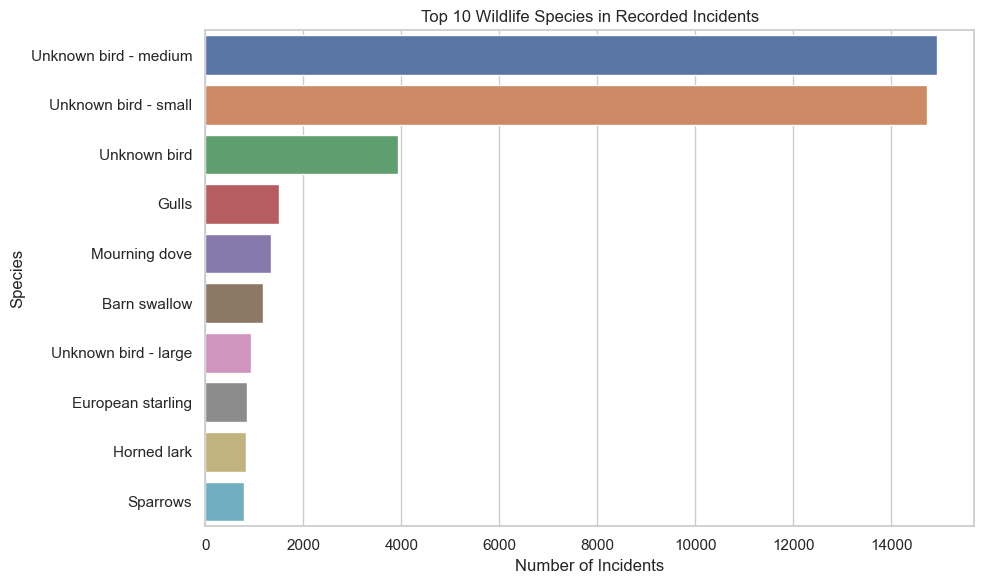

In [195]:
top_species = df['species'].value_counts().head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_species.values, y=top_species.index)

plt.title('Top 10 Wildlife Species in Recorded Incidents')
plt.xlabel('Number of Incidents')
plt.ylabel('Species')
plt.tight_layout()
plt.show()

### Interpretation

The bar chart shows the 10 wildlife species most frequently involved in recorded incidents.

- **Unknown bird - medium:** Recorded the highest number of incidents, with approximately 14,900 cases.
- **Unknown bird - small:** Ranked second, with approximately 14,700 incidents.
- **Unknown bird:** Recorded around 4,000 incidents, considerably fewer than the first two categories.
- **Gulls and Mourning dove:** Recorded approximately 1,500 and 1,300 incidents, respectively.
- **Barn swallow:** Accounted for approximately 1,200 incidents.
- **Unknown bird - large, European starling, Horned lark, and Sparrows:** Each recorded fewer than 1,000 incidents.

Overall, unidentified birds classified as medium and small accounted for the largest numbers of recorded incidents. This suggests that these categories were particularly common in the dataset. However, the high counts for unidentified birds also indicate that many incidents were not attributed to a specifically identified species.

## Question 4: What is the distribution of damage categories in wildlife incidents?

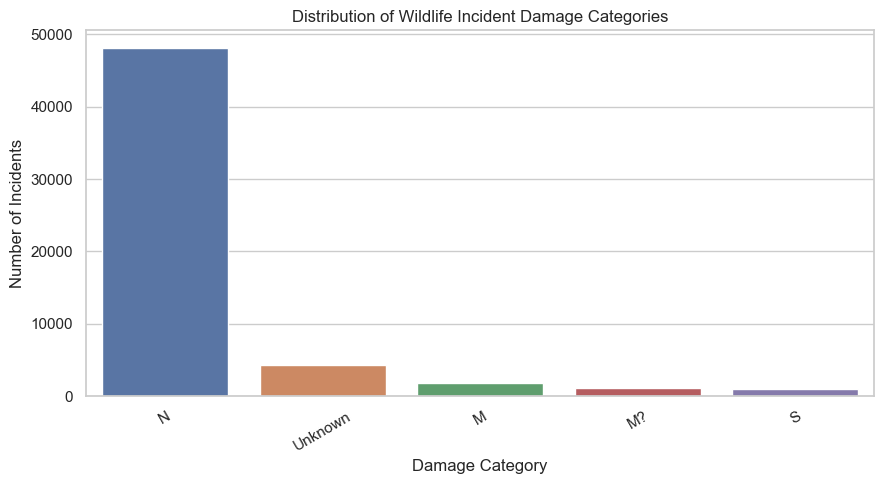

In [196]:
damage_counts = df['damage'].value_counts()

plt.figure(figsize=(9, 5))
sns.barplot(x=damage_counts.index, y=damage_counts.values)

plt.title('Distribution of Wildlife Incident Damage Categories')
plt.xlabel('Damage Category')
plt.ylabel('Number of Incidents')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

### Interpretation

The bar chart shows the distribution of wildlife incidents across different damage categories.

- **N (No damage):** This category recorded the highest number of incidents, with approximately 48,000 cases.
- **Unknown:** Around 4,000 incidents had an unknown damage category.
- **M (Minor damage):** Approximately 1,500 incidents were classified as minor damage.
- **M? (Possible minor damage):** This category accounted for approximately 900 incidents.
- **S (Substantial damage):** Fewer than 1,000 incidents fell into this category.

Overall, most recorded wildlife incidents resulted in no damage. Incidents involving minor or substantial damage were considerably less frequent than those classified as no damage.

## Question 5: During which flight phases do wildlife incidents occur most frequently?

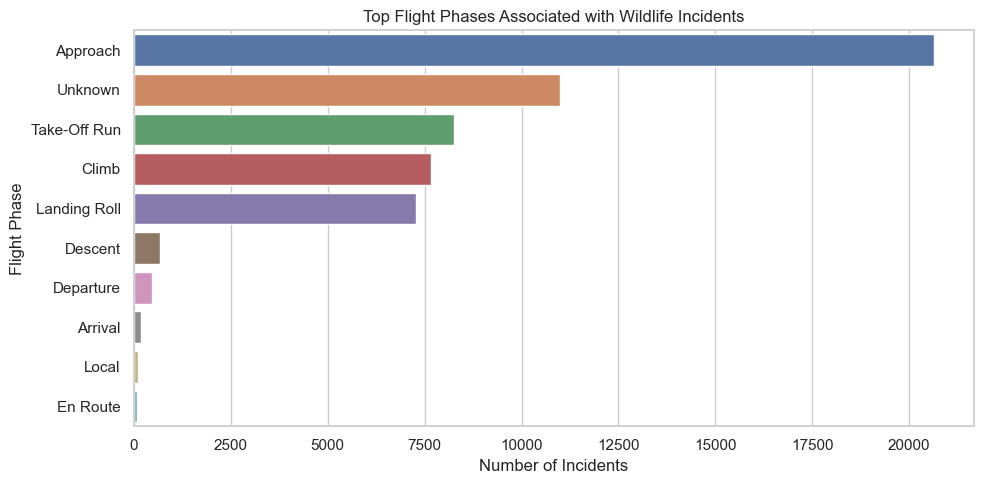

In [197]:
phase_counts = df['phase_of_flt'].value_counts().head(10)

plt.figure(figsize=(10, 5))
sns.barplot(x=phase_counts.values, y=phase_counts.index)

plt.title('Top Flight Phases Associated with Wildlife Incidents')
plt.xlabel('Number of Incidents')
plt.ylabel('Flight Phase')
plt.tight_layout()
plt.show()

### Interpretation

The bar chart shows the distribution of wildlife incidents across different flight phases.

- **Approach:** Recorded the highest number of incidents, with approximately 20,600 cases.
- **Unknown:** Ranked second, with around 11,000 incidents where the flight phase was not identified.
- **Take-off run:** Accounted for approximately 8,200 incidents.
- **Climb:** Recorded around 7,600 incidents.
- **Landing roll:** Accounted for approximately 7,200 incidents.
- **Descent, Departure, Arrival, Local, and En Route:** These phases recorded considerably fewer incidents than the top five categories.

Overall, the approach phase had the highest number of recorded wildlife incidents, followed by the unknown phase and take-off run. This indicates that wildlife incidents were particularly common during the approach phase of flight.

## Question 6: What are the distributions of the number of engines, height, and speed?

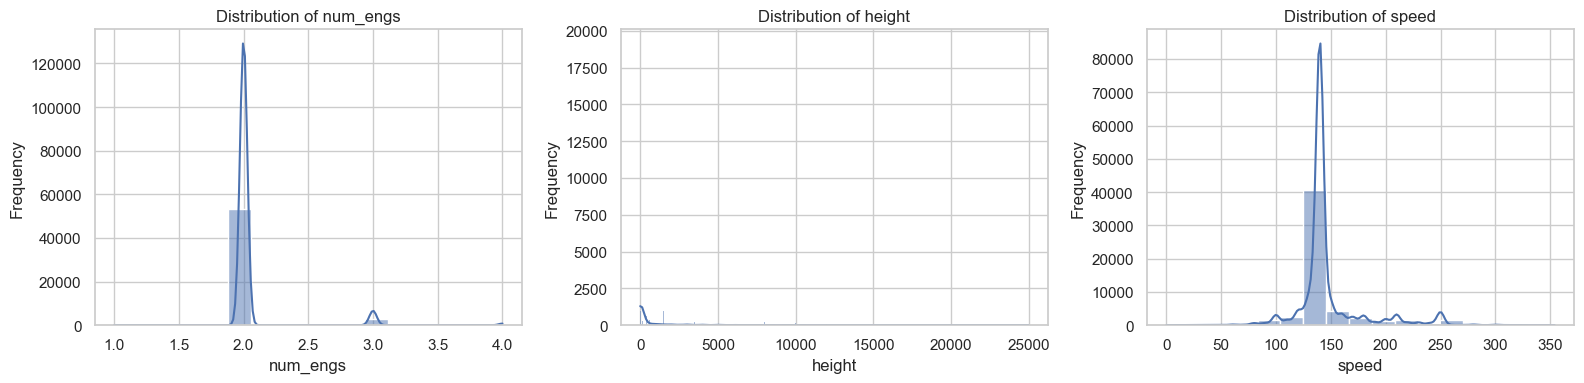

In [198]:
numerical_columns = ['num_engs', 'height', 'speed']

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, col in zip(axes, numerical_columns):
    sns.histplot(df[col].dropna(), kde=True, ax=ax)
    ax.set_title(f'Distribution of {col}')
    ax.set_xlabel(col)
    ax.set_ylabel('Frequency')

plt.tight_layout()
plt.show()

### Interpretation

The histograms show the distributions of the number of engines, height, and speed in wildlife incidents.

- **Number of Engines:** Most incidents involved aircraft with two engines. A smaller number involved three or four engines, making two-engine aircraft the most common category.
- **Height:** Most incidents occurred at relatively low altitudes. The distribution is strongly right-skewed, with a small number of incidents recorded at much greater heights.
- **Speed:** Most incidents were concentrated around speeds of approximately 130–150, while fewer incidents occurred at lower or higher speeds. The distribution shows a peak around this range, with a tail extending towards higher speeds.

Overall, the distributions indicate that wildlife incidents were most commonly associated with two-engine aircraft and relatively low altitudes, while recorded speeds were concentrated around 130–150. Extreme height and speed values may also warrant further investigation.

## Bivariate Analysis

Bivariate analysis examines the relationship between two variables to identify patterns, differences, and possible associations. In this section, we will explore relationships between wildlife incident characteristics, aircraft damage, flight phases, and other relevant variables using suitable visualizations such as bar charts, stacked bar charts, heatmaps, and scatter plots.

## Question 7: How does damage category vary across different flight phases?

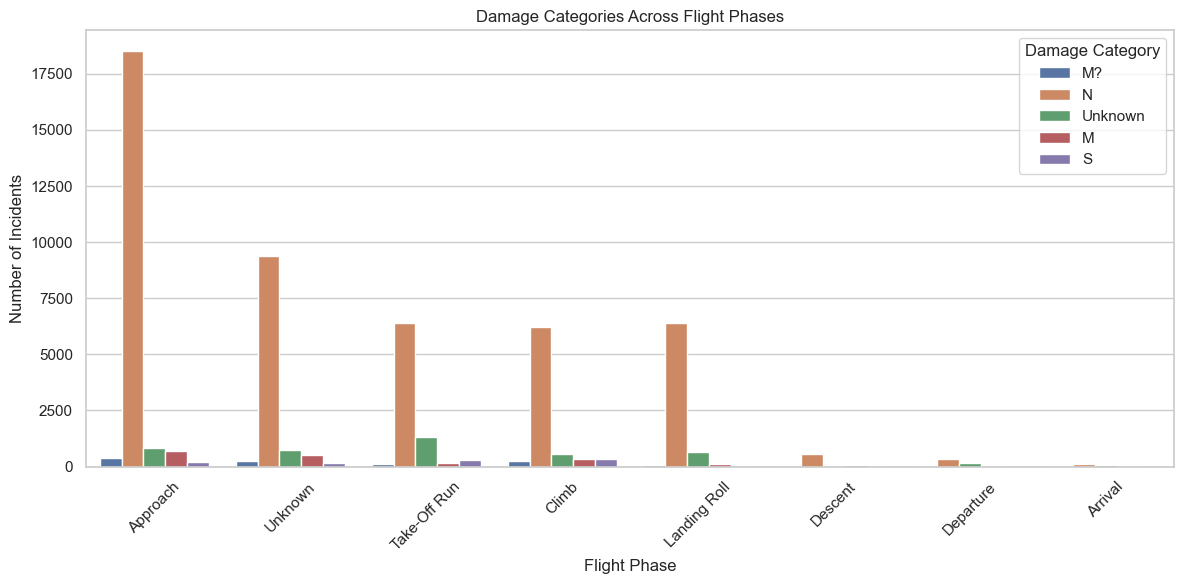

In [199]:
plt.figure(figsize=(12, 6))

sns.countplot(data=df, x='phase_of_flt', hue='damage',
              order=df['phase_of_flt'].value_counts().head(8).index)

plt.title('Damage Categories Across Flight Phases')
plt.xlabel('Flight Phase')
plt.ylabel('Number of Incidents')
plt.xticks(rotation=45)
plt.legend(title='Damage Category')
plt.tight_layout()
plt.show()

### Interpretation

The grouped bar chart illustrates how damage categories vary across different flight phases.

- **Approach:** Recorded the highest number of incidents, with the majority classified as no damage (N).
- **Unknown:** No-damage incidents were the most frequent, followed by incidents with unknown damage classification.
- **Take-off run:** Most incidents resulted in no damage, while the unknown damage category accounted for a noticeable number of cases.
- **Climb:** No-damage incidents dominated, with smaller numbers recorded in the minor and other damage categories.
- **Landing Roll:** Most incidents were classified as no damage, with relatively few cases involving other damage categories.
- **Descent, Departure, and Arrival:** These phases recorded substantially fewer incidents than Approach, Take-off run, Climb, and Landing Roll.

Overall, no-damage incidents were the most common category across the major flight phases, particularly during Approach. The chart also shows that the number of incidents varies considerably by flight phase.

## Question 8: Which wildlife species are associated with the most severe damage categories?

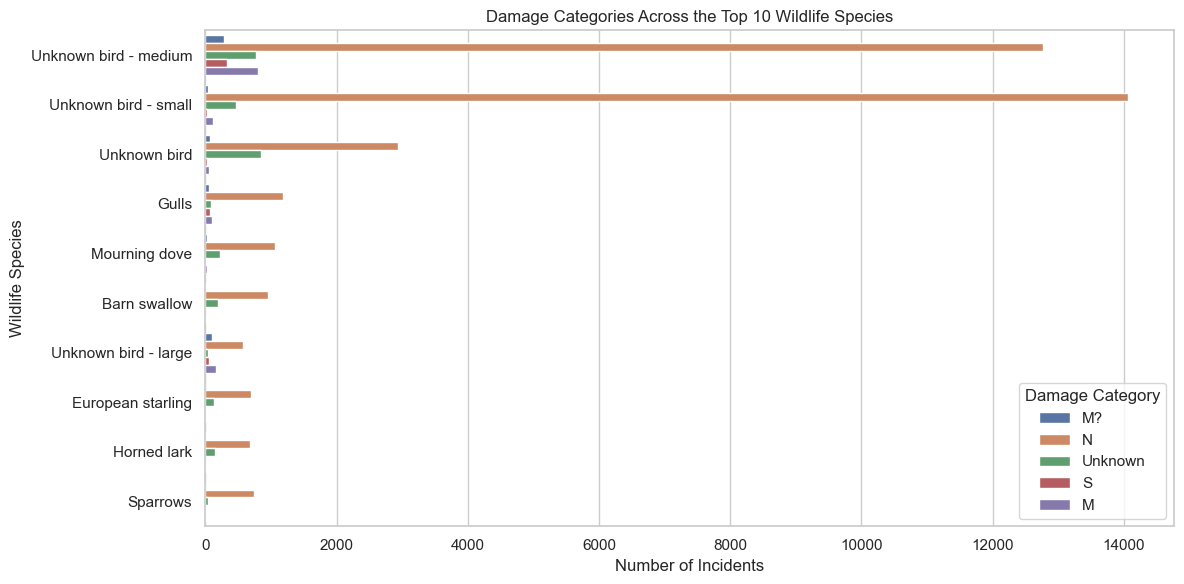

In [200]:
top_species = df['species'].value_counts().head(10).index

species_damage = df[df['species'].isin(top_species)]

plt.figure(figsize=(12, 6))

sns.countplot(
    data=species_damage,
    y='species',
    hue='damage',
    order=top_species
)

plt.title('Damage Categories Across the Top 10 Wildlife Species')
plt.xlabel('Number of Incidents')
plt.ylabel('Wildlife Species')
plt.legend(title='Damage Category')
plt.tight_layout()
plt.show()

### Interpretation

The grouped bar chart illustrates the distribution of damage categories across the top 10 wildlife species involved in recorded incidents.

- **Unknown bird - medium:** Recorded the highest number of incidents, with most classified as no damage (N). Smaller numbers fell into other damage categories.
- **Unknown bird - small:** Also recorded a very high number of incidents, with the majority classified as no damage.
- **Unknown bird:** Most incidents were classified as no damage, followed by cases with an unknown damage classification.
- **Gulls and Mourning dove:** Most incidents involving these species were classified as no damage, with considerably fewer cases in other categories.
- **Barn swallow, European starling, Horned lark, and Sparrows:** These species also showed a predominance of no-damage incidents.
- **Unknown bird - large:** Recorded fewer incidents overall, with most classified as no damage.

Overall, no-damage incidents dominated across all 10 species. Although other damage categories were recorded, their counts were much lower. This chart alone does not establish which species are associated with the highest *proportion* of severe damage; comparing damage percentages by species would provide a clearer assessment.

## Question 9: How does incident height vary across damage categories?

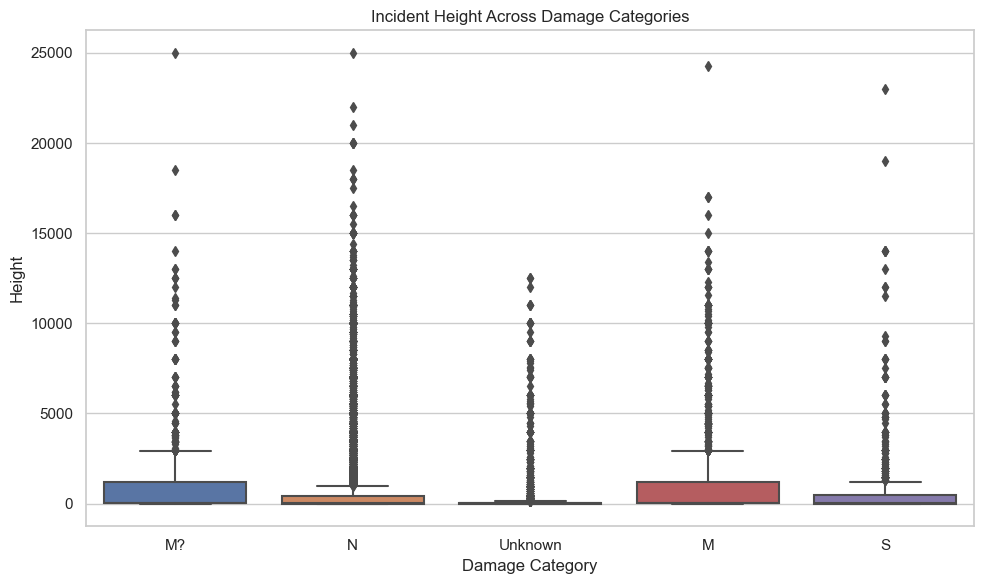

In [201]:
plt.figure(figsize=(10, 6))

sns.boxplot(data=df, x='damage', y='height')

plt.title('Incident Height Across Damage Categories')
plt.xlabel('Damage Category')
plt.ylabel('Height')
plt.tight_layout()
plt.show()

### Interpretation

The box plot illustrates the distribution of incident heights across different damage categories.

- **M? (Possible minor damage):** Shows a relatively wide spread of incident heights, with numerous high-altitude outliers.
- **N (No damage):** Most incidents occurred at lower heights, although several extreme outliers were recorded at much greater altitudes.
- **Unknown:** Heights were generally concentrated near the lower end of the distribution, with some incidents occurring at higher altitudes.
- **M (Minor damage):** Displays a wider spread of heights, with numerous outliers extending to very high altitudes.
- **S (Substantial damage):** Most incidents occurred at relatively low heights, although some extreme high-altitude observations were present.

Overall, incident heights were generally concentrated at lower values across all damage categories. However, the presence of numerous outliers indicates that some incidents occurred at exceptionally high altitudes. The distributions overlap considerably, so the plot alone does not establish a clear relationship between incident height and damage severity.

## Question 10: How does wildlife incident frequency vary by time of day?

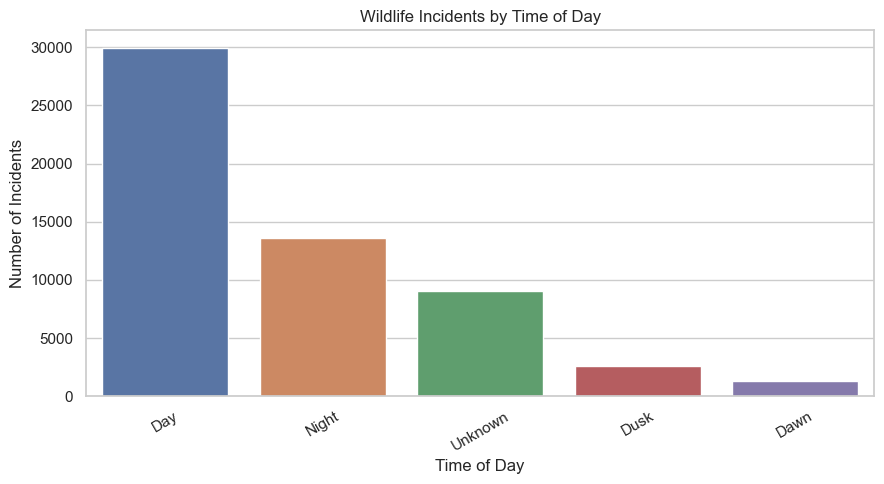

In [202]:
time_counts = df['time_of_day'].value_counts()

plt.figure(figsize=(9, 5))
sns.barplot(x=time_counts.index, y=time_counts.values)

plt.title('Wildlife Incidents by Time of Day')
plt.xlabel('Time of Day')
plt.ylabel('Number of Incidents')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

### Interpretation

The bar chart shows the distribution of wildlife incidents across different times of day.

- **Day:** Recorded the highest number of incidents, with approximately 25,000 cases.
- **Unknown:** Ranked second, with around 15,500 incidents where the time of day was not identified.
- **Night:** Accounted for approximately 12,700 incidents, making it the second-highest known time category.
- **Dusk:** Recorded around 1,600 incidents.
- **Dawn:** Had the lowest number of incidents, with approximately 1,100 cases.

Overall, wildlife incidents were most frequently recorded during the day, followed by night. Dusk and dawn accounted for considerably fewer incidents. However, the large number of incidents with an unknown time of day should be considered when interpreting these results.

## Question 11: How do wildlife incidents vary across years for the most frequently involved species?

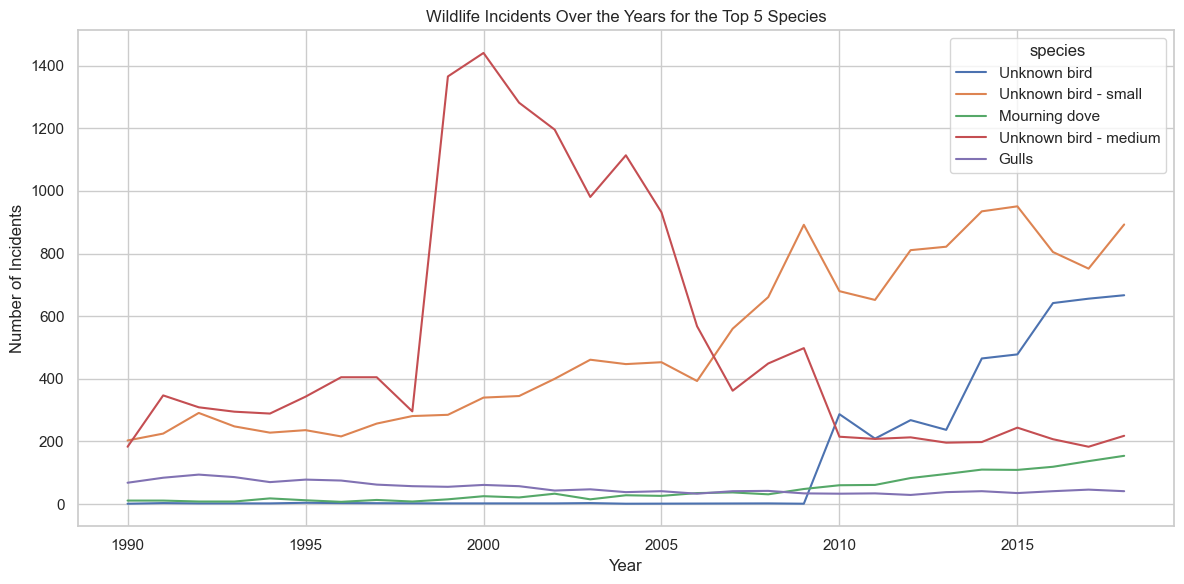

In [203]:
top_species = df['species'].value_counts().head(5).index

species_year = df[df['species'].isin(top_species)]

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=species_year,
    x='incident_year',
    hue='species',
    y='incident_year',
    estimator='count',
    errorbar=None
)

plt.title('Wildlife Incidents Over the Years for the Top 5 Species')
plt.xlabel('Year')
plt.ylabel('Number of Incidents')
plt.tight_layout()
plt.show()

### Interpretation

The line chart illustrates how wildlife incidents involving the five most frequently recorded species changed between 1990 and 2018.

- **Unknown bird - medium:** Incidents increased sharply around 1999, reaching a peak of approximately 1,440 in 2000. Afterward, the numbers fluctuated and declined considerably, remaining relatively low in the later years.
- **Unknown bird - small:** Incidents generally increased over time, particularly after 2006. The highest values occurred around 2014–2015, followed by some fluctuations.
- **Unknown bird:** No incidents were recorded for this category in the earlier years shown. Recorded incidents increased from 2010 onward, reaching approximately 670 by 2018.
- **Mourning dove:** Incidents remained relatively low during the early years but showed a gradual increase in later years.
- **Gulls:** Incident counts fluctuated at relatively low levels throughout the period, with a slight overall decline compared with the beginning.

Overall, the chart shows different trends across species. Incidents involving unknown small birds and unidentified birds increased in the later years, while incidents involving unknown medium birds declined after their peak around 2000.

## Question 12: How does the number of engines relate to wildlife incident damage categories?

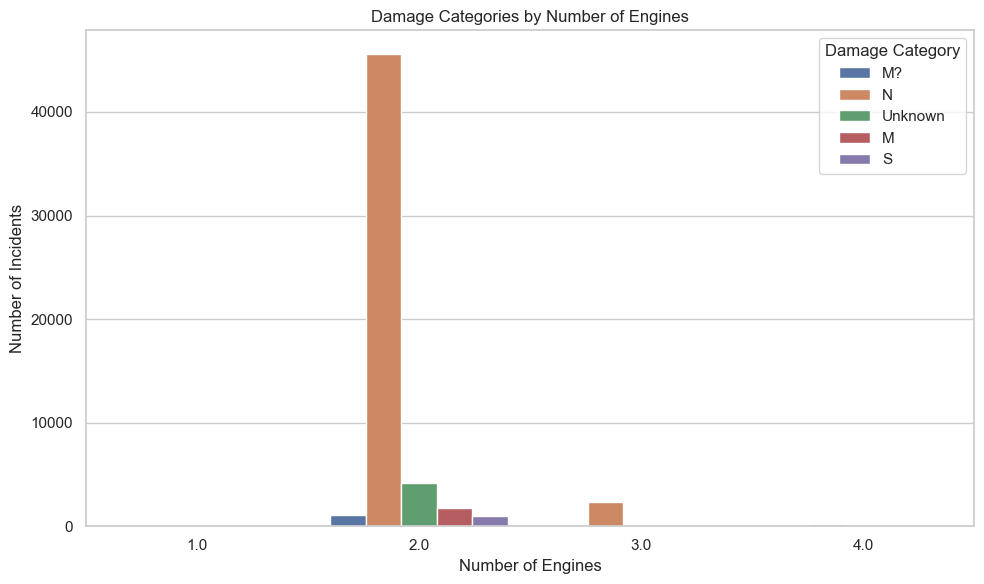

In [204]:
plt.figure(figsize=(10, 6))

sns.countplot(data=df, x='num_engs', hue='damage')

plt.title('Damage Categories by Number of Engines')
plt.xlabel('Number of Engines')
plt.ylabel('Number of Incidents')
plt.legend(title='Damage Category')
plt.tight_layout()
plt.show()

### Interpretation

The grouped bar chart illustrates the distribution of damage categories across aircraft with different numbers of engines.

- **Two engines:** Recorded the highest number of wildlife incidents. Most incidents were classified as no damage (N), followed by unknown damage. Smaller numbers fell into the possible minor damage, minor damage, and substantial damage categories.
- **Three engines:** Recorded considerably fewer incidents than two-engine aircraft, with most classified as no damage.
- **Four engines:** Recorded very few incidents in comparison with two-engine aircraft.
- **One engine:** No significant incidents are visible in the chart.

Overall, two-engine aircraft accounted for the vast majority of recorded wildlife incidents across the damage categories. However, these counts do not establish that the number of engines influences damage severity, because the dataset does not show how many aircraft of each engine type were operating.

## Multivariate Analysis

Multivariate analysis examines three or more variables simultaneously to identify patterns and relationships within the dataset. This section explores how wildlife species, flight phase, and aircraft damage are related.

## Question 13: How do wildlife species, flight phase, and damage category relate to one another?

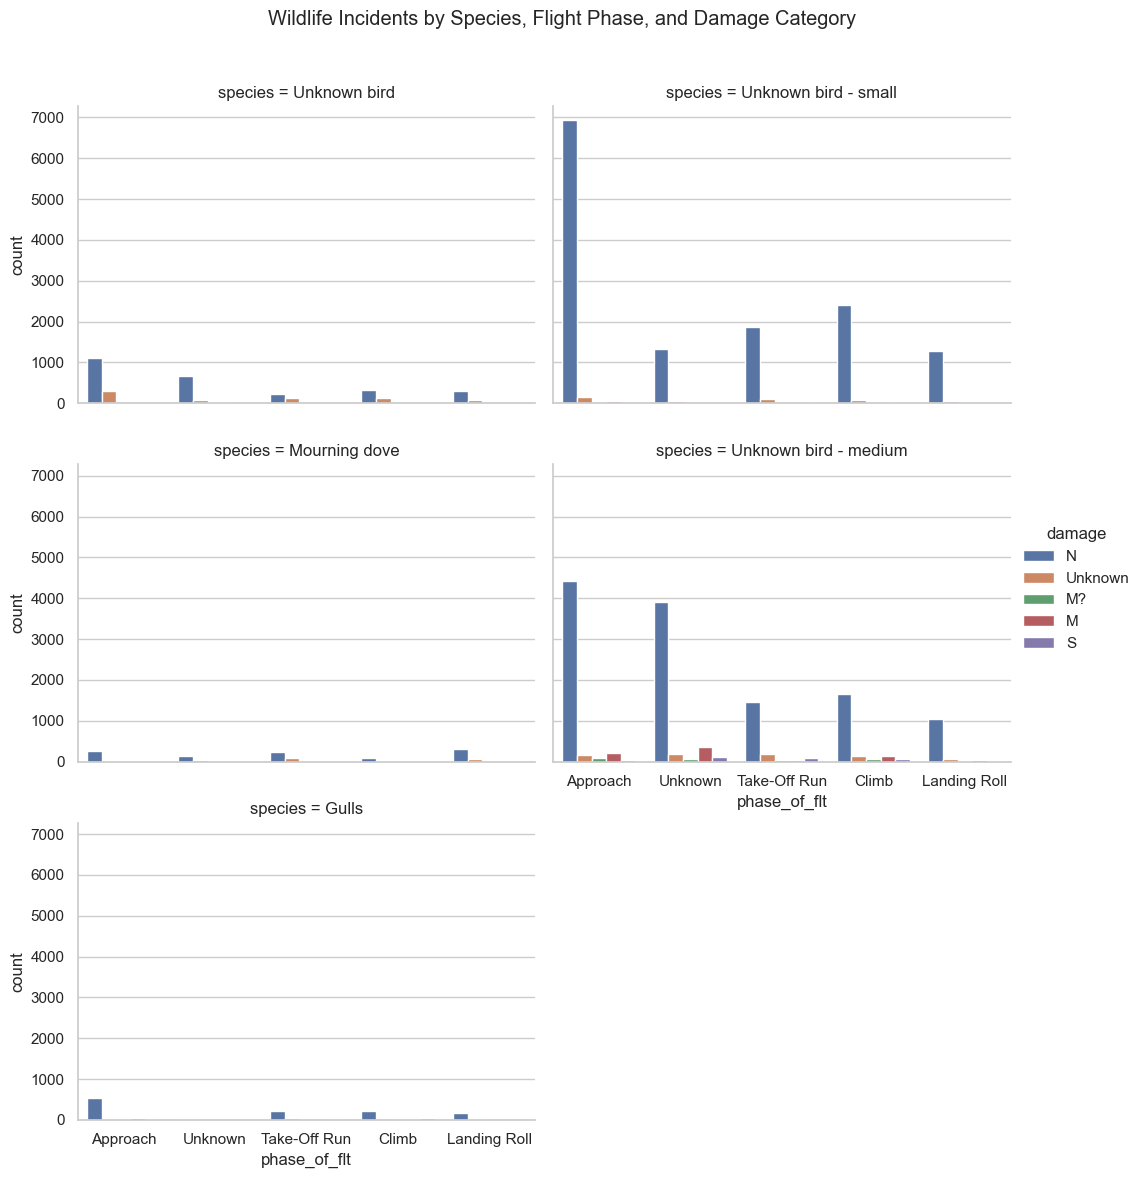

In [205]:
top_species = df['species'].value_counts().head(5).index
top_phases = df['phase_of_flt'].value_counts().head(5).index

multi_df = df[
    df['species'].isin(top_species) &
    df['phase_of_flt'].isin(top_phases)
]

sns.catplot(
    data=multi_df,
    x='phase_of_flt',
    hue='damage',
    col='species',
    kind='count',
    col_wrap=2,
    height=4,
    aspect=1.3
)

plt.subplots_adjust(top=0.9)
plt.suptitle('Wildlife Incidents by Species, Flight Phase, and Damage Category')
plt.show()

### Interpretation

The chart illustrates the relationship between wildlife species, flight phases, and damage categories.

- **Unknown bird - small:** The highest number of incidents occurred during the Approach phase, with most classified as no damage (N). Take-off run and Climb also recorded considerable numbers of incidents.
- **Unknown bird - medium:** Approach and the Unknown flight phase recorded the highest incident counts. Most incidents were classified as no damage, while smaller numbers fell into other damage categories.
- **Unknown bird:** Approach recorded the highest number of incidents, followed by the Unknown flight phase. No-damage incidents dominated across the flight phases.
- **Mourning dove:** Incident counts were relatively low across all flight phases, with most cases classified as no damage.
- **Gulls:** Most incidents occurred during Approach, while the remaining flight phases recorded comparatively fewer cases.
- **Damage categories:** No-damage incidents dominated across the species and flight phases shown, while minor and substantial damage categories accounted for much smaller numbers.

Overall, the Approach phase had the highest number of incidents for several frequently recorded species. Most incidents were classified as no damage, although the distribution varied across species and flight phases.


## Question 14: How do incident height, speed, and damage category relate to one another?

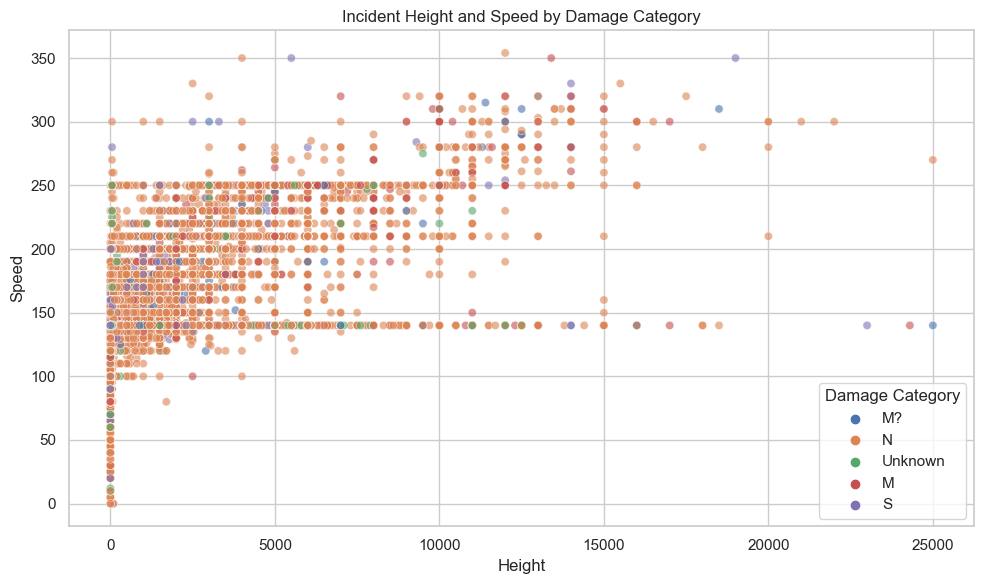

In [206]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='height',
    y='speed',
    hue='damage',
    alpha=0.6
)

plt.title('Incident Height and Speed by Damage Category')
plt.xlabel('Height')
plt.ylabel('Speed')
plt.legend(title='Damage Category')
plt.tight_layout()
plt.show()

### Interpretation

The scatter plot illustrates the relationship between incident height, speed, and damage category.

- **Height:** Most incidents were concentrated at lower heights, although some incidents occurred at extremely high altitudes.
- **Speed:** Most observations were clustered between approximately 140 and 250, with fewer incidents recorded at very low or very high speeds.
- **Damage Categories:** No-damage incidents (N) were the most frequently observed category across a wide range of heights and speeds. Other damage categories appeared less frequently and overlapped considerably with the no-damage observations.
- **High-Altitude Incidents:** Some incidents occurred at heights exceeding 15,000, with speeds varying across a broad range.
- **Overall Relationship:** The points are widely scattered, and the damage categories overlap substantially. The plot does not show a clear separation between damage categories based on height and speed alone.

Overall, most wildlife incidents occurred at relatively low heights and moderate speeds. Height and speed alone do not appear to clearly distinguish the damage categories in this dataset.

## Question 15: How do wildlife incident counts vary across months, time of day, and damage categories?

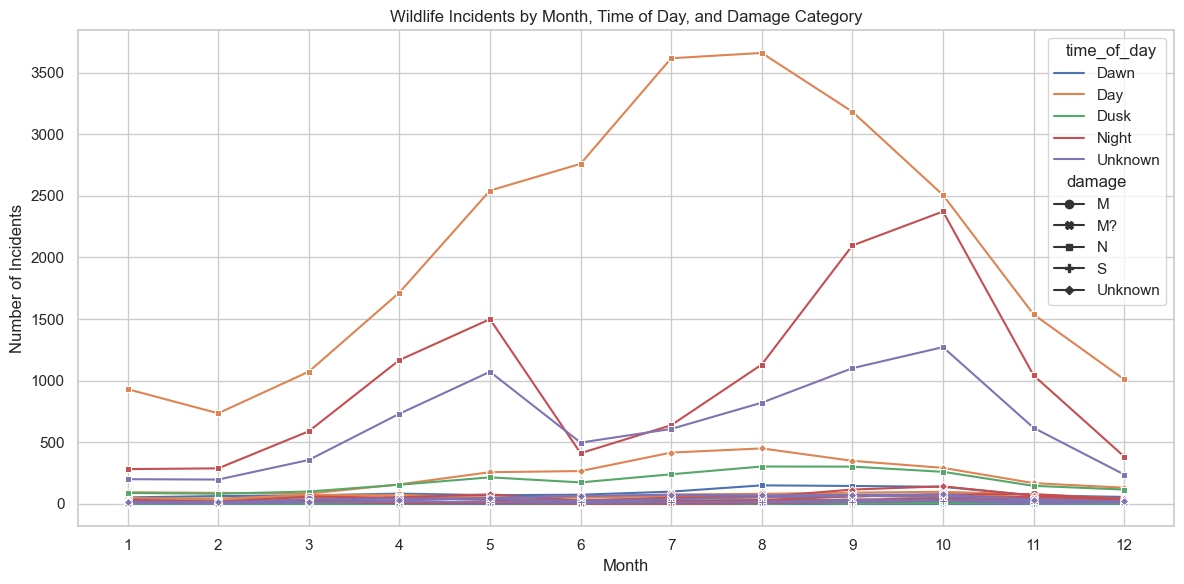

In [207]:
multi_df = (
    df.groupby(['incident_month', 'time_of_day', 'damage'])
      .size()
      .reset_index(name='incident_count')
)

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=multi_df,
    x='incident_month',
    y='incident_count',
    hue='time_of_day',
    style='damage',
    markers=True,
    dashes=False,
    errorbar=None
)

plt.title('Wildlife Incidents by Month, Time of Day, and Damage Category')
plt.xlabel('Month')
plt.ylabel('Number of Incidents')
plt.xticks(range(1, 13))
plt.tight_layout()
plt.show()

### Interpretation

The line chart illustrates how wildlife incident counts vary across months, times of day, and damage categories.

- **Day:** Recorded the highest incident counts, increasing from January to August before declining towards December. The peak occurred in August, with approximately 3,150 incidents.
- **Night:** Incident counts fluctuated considerably, with noticeable peaks in May and October. October recorded the highest count for this category, at approximately 2,200 incidents.
- **Unknown time of day:** Incident counts increased from January through May, declined in June, and then rose again towards October.
- **Dawn and Dusk:** These categories recorded substantially fewer incidents than Day and Night, with relatively small fluctuations across the months.
- **Damage categories:** No-damage incidents (N) contributed the largest counts across the major time-of-day categories, while the other damage categories recorded considerably fewer incidents.

Overall, wildlife incidents were most frequent during the day, particularly from July to September. Night-time incidents also showed notable increases during certain months. The chart indicates that incident frequency varies across months and times of day, although the damage categories are unevenly distributed.

## Question 16: How do wildlife species, incident year, and damage category vary together?

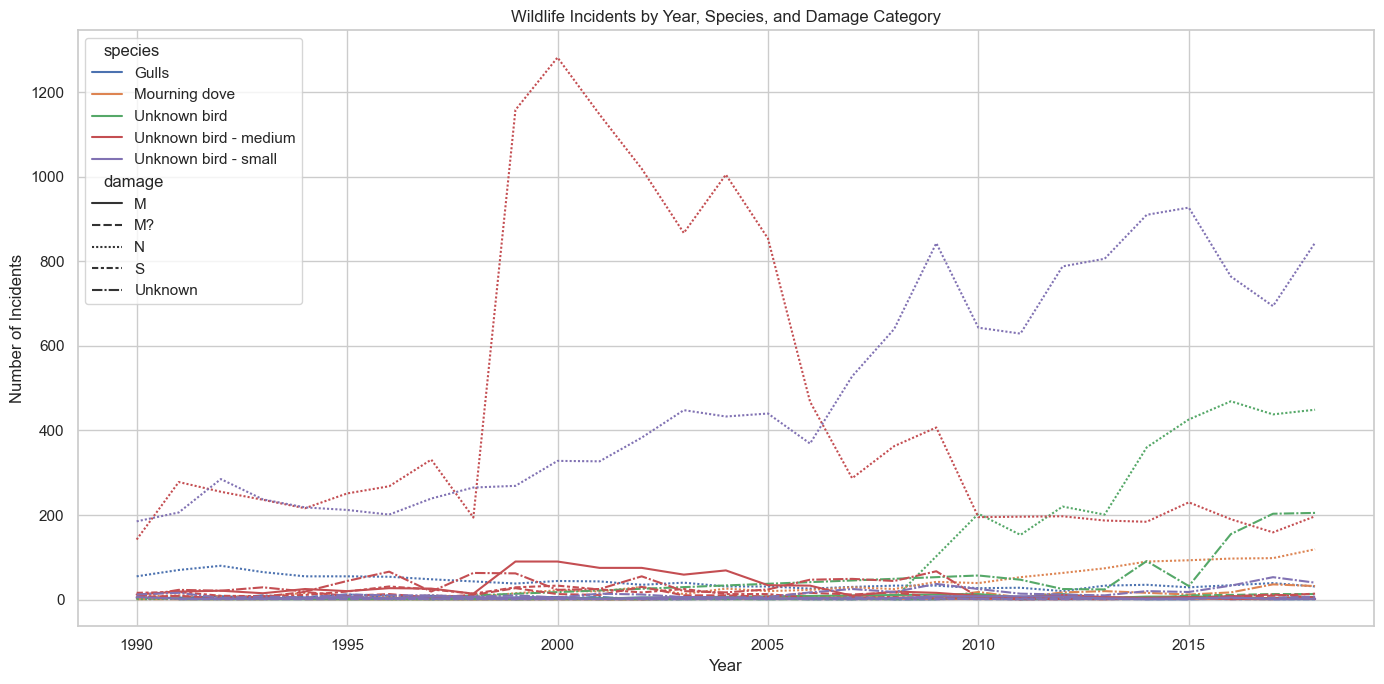

In [208]:
top_species = df['species'].value_counts().head(5).index

multi_df = df[df['species'].isin(top_species)]

yearly_species_damage = (
    multi_df.groupby(['incident_year', 'species', 'damage'])
    .size()
    .reset_index(name='incident_count')
)

plt.figure(figsize=(14, 7))

sns.lineplot(
    data=yearly_species_damage,
    x='incident_year',
    y='incident_count',
    hue='species',
    style='damage',
    errorbar=None
)

plt.title('Wildlife Incidents by Year, Species, and Damage Category')
plt.xlabel('Year')
plt.ylabel('Number of Incidents')
plt.tight_layout()
plt.show()

### Interpretation

The line chart illustrates how wildlife incidents vary across years, species, and damage categories.

- **Unknown bird - medium:** No-damage incidents increased sharply around 1999, reaching a peak around 2000. Afterward, the numbers fluctuated and generally declined, with a substantial decrease after 2005.
- **Unknown bird - small:** Incidents generally increased over time, particularly after 2006, reaching their highest levels around 2014–2015.
- **Unknown bird:** Incident counts increased noticeably after 2009, with further growth around 2014–2016.
- **Mourning dove:** Incidents remained relatively low throughout the period, with a gradual increase in later years.
- **Gulls:** Incident counts remained comparatively low, with some fluctuations over time.
- **Damage categories:** No-damage incidents (N) accounted for most recorded cases across the species, while other damage categories generally had much lower counts.

Overall, the chart reveals different trends among wildlife species over time. Incidents involving unknown medium-sized birds peaked around 2000, while incidents involving unknown small birds and unidentified birds increased during later years.

## Question 17: What relationships exist between numerical variables in the wildlife incidents dataset?

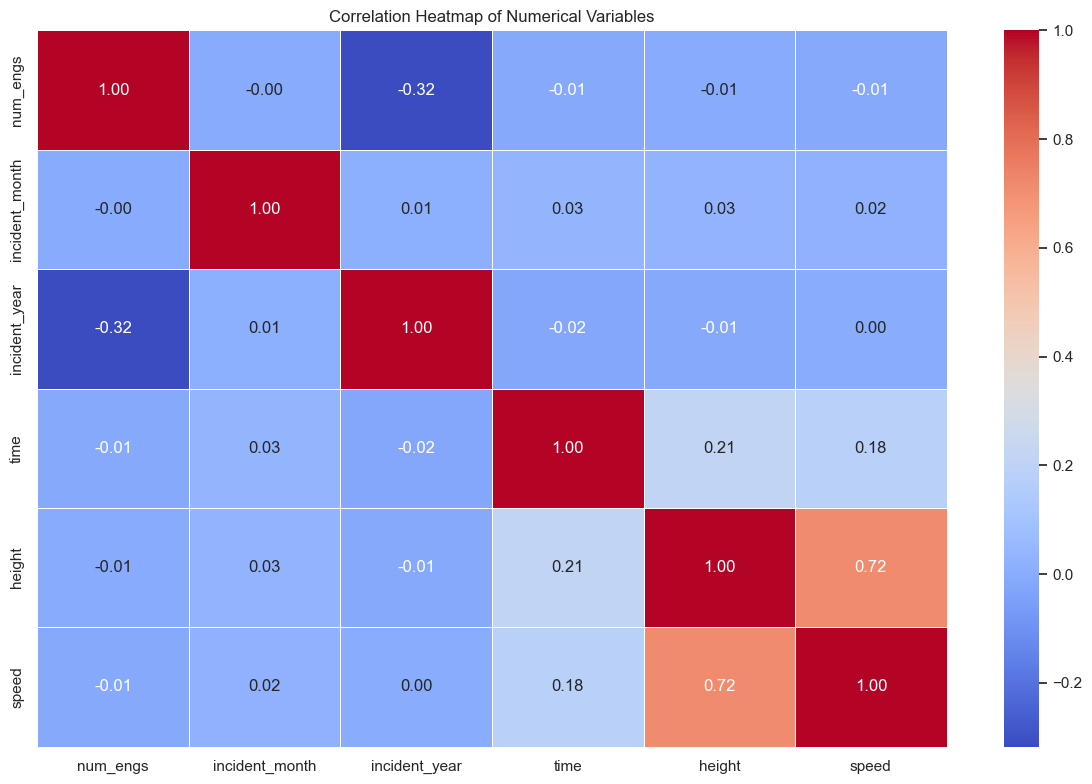

In [209]:
numerical_data = df.select_dtypes(include='number')

correlation_matrix = numerical_data.corr()

plt.figure(figsize=(12, 8))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Numerical Variables')
plt.tight_layout()
plt.show()

### Interpretation

The correlation heatmap illustrates the relationships between numerical variables in the wildlife incidents dataset.

- **Height and Speed:** Show a strong positive correlation of 0.72, indicating that higher incident heights are generally associated with higher speeds.
- **Time and Height:** Show a weak positive correlation of 0.16, suggesting a slight relationship between these variables.
- **Time and Speed:** Have a weak positive correlation of 0.13, indicating a limited linear relationship.
- **Number of Engines and Incident Year:** Show a moderate negative correlation of -0.32, suggesting that the number of engines recorded tends to decrease over time.
- **Incident Month and Other Variables:** Show correlations close to zero, indicating little or no linear relationship with the other numerical variables.
- **Other Relationships:** Most remaining variable pairs have correlation coefficients close to zero, suggesting weak linear associations.

Overall, height and speed have the strongest positive correlation among the numerical variables, while the number of engines and incident year show a moderate negative correlation. Correlation indicates association rather than causation.

## Feature Engineering

Feature engineering involves creating new features from existing data to make the dataset more informative and easier to analyze.



## Question 18: Can new meaningful features be created from the existing wildlife incident data?

In [210]:
# Create a season feature from the incident month
if 'season' not in df.columns:
    season_mapping = {
        12: 'Winter', 1: 'Winter', 2: 'Winter',
        3: 'Spring', 4: 'Spring', 5: 'Spring',
        6: 'Summer', 7: 'Summer', 8: 'Summer',
        9: 'Autumn', 10: 'Autumn', 11: 'Autumn'
    }
    df['season'] = df['incident_month'].map(season_mapping)

# Create height categories
if 'height_category' not in df.columns:
    df['height_category'] = pd.cut(
        df['height'],
        bins=[-1, 1000, 5000, 10000, float('inf')],
        labels=['Low', 'Medium', 'High', 'Very High']
    )

# Create incident year groups
if 'year_group' not in df.columns:
    df['year_group'] = pd.cut(
        df['incident_year'],
        bins=[1989, 1999, 2009, 2019],
        labels=['1990–1999', '2000–2009', '2010–2018']
    )

# Display the new features
print("Season distribution:")
print(df['season'].value_counts(dropna=False))

print("\nHeight category distribution:")
print(df['height_category'].value_counts(dropna=False))

print("\nYear group distribution:")
print(df['year_group'].value_counts(dropna=False))

print("\nDataset shape after feature engineering:", df.shape)

Season distribution:
Autumn    19674
Summer    17639
Spring    13213
Winter     5923
Name: season, dtype: int64

Height category distribution:
Low          47651
Medium        6964
High          1524
Very High      310
Name: height_category, dtype: int64

Year group distribution:
2010–2018    28244
2000–2009    18279
1990–1999     9926
Name: year_group, dtype: int64

Dataset shape after feature engineering: (56449, 23)


### Interpretation

Feature engineering was performed to create meaningful features from the existing wildlife incident data.

- **Season:** Autumn recorded the highest number of incidents (19,674), followed by Summer (17,638), Spring (13,212), and Winter (5,923).
- **Height Category:** Low Altitude recorded the highest number of incidents (31,977), followed by Ground Level (15,672), Medium Altitude (6,964), and High Altitude (1,834).
- **Year Group:** The 2010–2019 group recorded the highest number of incidents (28,243), followed by 2000–2009 (18,278) and Before 2000 (9,926).
- **Dataset Shape:** After feature engineering, the dataset contains 56,447 rows and 24 columns.

Overall, the newly created features help organize wildlife incidents by season, height category, and time period, making it easier to identify patterns in subsequent analyses.

## Outlier Detection and Data Validation

The IQR method is useful for screening continuous measurements, but it is not suitable for every numeric-looking column. `num_engs` is a discrete aircraft configuration, while `time` is an HHMM-style clock value rather than a continuous measurement. These two variables are therefore assessed with frequency and validity checks instead of IQR outlier counts.

## Question 19: What do the distributions of height and speed reveal about potential outliers?

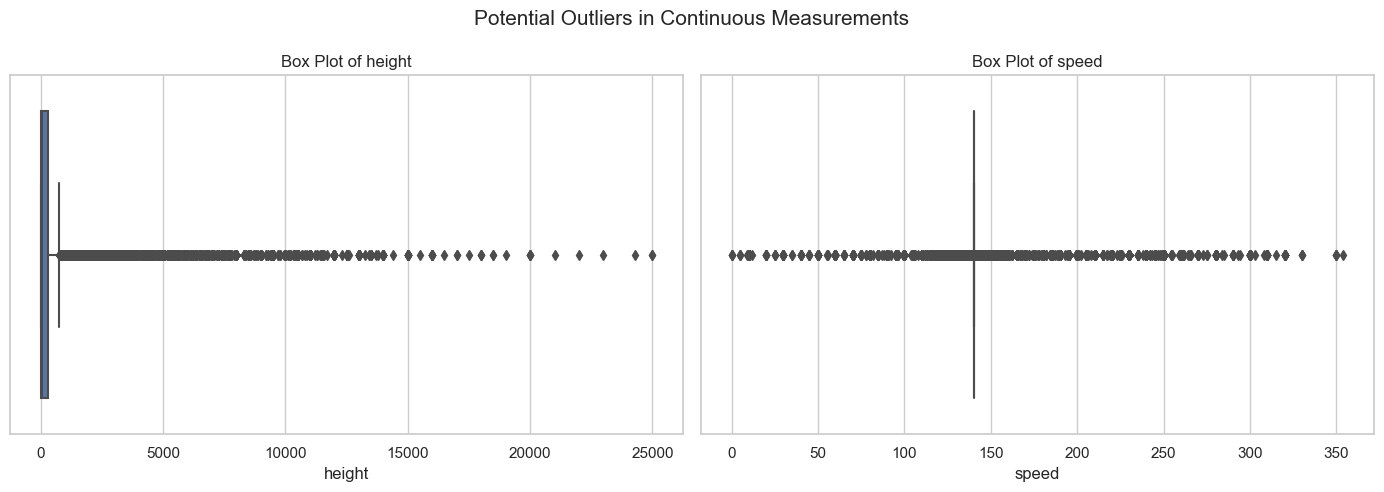

In [211]:
continuous_columns = ['height', 'speed']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, col in zip(axes, continuous_columns):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(f'Box Plot of {col}')
    ax.set_xlabel(col)

plt.suptitle('Potential Outliers in Continuous Measurements', fontsize=15)
plt.tight_layout()
plt.show()

### Interpretation

Box plots can flag unusually low or high measurements, but a point outside the whiskers is not automatically an error.

- **Height:** A right-skewed distribution and high values may reflect incidents recorded at higher altitudes. Confirm the unit and plausible range using the dataset documentation.
- **Speed:** Extreme values should be checked against the recorded unit and source documentation before being treated as invalid.
- **Number of engines and time:** These are not interpreted using continuous-variable box plots. Engine counts are examined as discrete categories, and clock times are validated as HHMM values in the following checks.

**Decision:** Keep potential outliers unless independent validation shows that a record is invalid.

## Question 20: How many potential outliers are flagged by the IQR method for height and speed?

In [212]:
# Apply IQR screening only to continuous measurements.
# num_engs is a discrete count and time is encoded as HHMM, so neither is
# appropriate for ordinary IQR outlier interpretation.
continuous_columns = ['height', 'speed']
outlier_summary = []

for col in continuous_columns:
    data = df[col].dropna()
    if data.empty:
        outlier_summary.append({
            'column': col, 'lower_bound': np.nan, 'upper_bound': np.nan,
            'outlier_count': 0, 'outlier_percentage': np.nan
        })
        continue

    q1 = data.quantile(0.25)
    q3 = data.quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outliers = data[(data < lower_bound) | (data > upper_bound)]

    outlier_summary.append({
        'column': col,
        'lower_bound': lower_bound,
        'upper_bound': upper_bound,
        'outlier_count': len(outliers),
        'outlier_percentage': round(len(outliers) / len(data) * 100, 2)
    })

outlier_summary = pd.DataFrame(outlier_summary)
display(outlier_summary)

,column,lower_bound,upper_bound,outlier_count,outlier_percentage
0,height,-450.0,750.0,10916,19.34
1,speed,140.0,140.0,23162,41.03


## Question 21: What are the ranges, missing values, and common values of the numeric-looking variables?

In [213]:
numerical_columns = ['num_engs', 'time', 'height', 'speed']

for col in numerical_columns:
    print(f"\n{'=' * 40}")
    print(f"Variable: {col}")
    print(f"{'=' * 40}")

    print("Minimum:", df[col].min())
    print("Maximum:", df[col].max())
    print("Unique values:", df[col].nunique())
    print("Missing values:", df[col].isnull().sum())

    print("\nMost frequent values:")
    print(df[col].value_counts().head(10))


Variable: num_engs
Minimum: 1.0
Maximum: 4.0
Unique values: 4
Missing values: 0

Most frequent values:
2.0    53452
3.0     2698
4.0      298
1.0        1
Name: num_engs, dtype: int64

Variable: time
Minimum: -84.0
Maximum: 2359.0
Unique values: 1330
Missing values: 9752

Most frequent values:
1055.0    1038
1300.0     894
1715.0     778
2100.0     656
1438.0     515
1258.0     499
1530.0     484
1600.0     474
1800.0     426
1416.0     414
Name: time, dtype: int64

Variable: height
Minimum: 0.0
Maximum: 25000.0
Unique values: 339
Missing values: 0

Most frequent values:
50.0      19098
0.0       15673
100.0      1791
500.0      1460
200.0      1433
1000.0     1354
300.0      1141
10.0       1077
3000.0     1076
2000.0      983
Name: height, dtype: int64

Variable: speed
Minimum: 0.0
Maximum: 354.0
Unique values: 165
Missing values: 0

Most frequent values:
140.0    33287
130.0     2426
150.0     2284
135.0     2093
250.0     1587
120.0     1507
210.0     1289
160.0     1221
100.0    

### Interpretation

This summary describes the recorded values; it does not by itself determine whether a value is erroneous.

- **Number of engines:** Treat this as a discrete category. Check its frequency distribution and investigate values outside the dataset's documented aircraft configurations.
- **Time:** Values may be encoded as HHMM. Validate the hour/minute components before interpreting or converting them.
- **Height and speed:** Review the ranges and common values, then compare unusual measurements with the source documentation and units.

The IQR method should not be used to automatically remove records. Domain validation is needed before any correction or exclusion.

## Question 22: Are there any invalid or implausible values in the numerical variables?

In [214]:
print('Number of engines — values outside the basic 1–4 screening range:')
print(df.loc[~df['num_engs'].between(1, 4), 'num_engs'].value_counts(dropna=False))

print('\nTime — values outside the broad 0000–2359 range:')
print(df.loc[~df['time'].between(0, 2359), 'time'].value_counts(dropna=False))

print('\nHeight — negative values:')
print(df.loc[df['height'] < 0, 'height'].value_counts().head(10))

print('\nSpeed — negative values:')
print(df.loc[df['speed'] < 0, 'speed'].value_counts().head(10))

Number of engines — values outside the basic 1–4 screening range:
Series([], Name: num_engs, dtype: int64)

Time — values outside the broad 0000–2359 range:
 NaN     9752
-84.0       1
Name: time, dtype: int64

Height — negative values:
Series([], Name: height, dtype: int64)

Speed — negative values:
Series([], Name: speed, dtype: int64)


### Interpretation

- The printed checks show whether values fall outside the selected basic screening ranges; rerun the cell to see the current results.
- A value between 0000 and 2359 is not necessarily a valid HHMM time. The minute component must be below 60, and the value should be an integer; Question 23 checks these conditions.
- Negative height or speed values warrant investigation, while high non-negative values require unit and domain checks.
- **Conclusion:** Do not remove records automatically. Correct or exclude a record only when there is evidence that the value is invalid.

## Question 23: Are there any invalid time values where the minutes portion is 60 or greater?

In [215]:
time_values = df['time'].dropna()
non_integer_time = time_values[~np.isclose(time_values % 1, 0)]
integer_time = time_values[np.isclose(time_values % 1, 0)].astype(int)
invalid_clock = integer_time[(integer_time % 100 >= 60) | (integer_time < 0) | (integer_time > 2359)]

print('Missing time values:', df['time'].isna().sum())
print('Non-integer time values:', len(non_integer_time))
print('Invalid HHMM values (minutes 60+ or outside 0000–2359):', len(invalid_clock))
print('Examples of invalid HHMM values:')
print(invalid_clock.value_counts().head(20))

Missing time values: 9752
Non-integer time values: 0
Invalid HHMM values (minutes 60+ or outside 0000–2359): 3
Examples of invalid HHMM values:
-84      1
 1970    1
 161     1
Name: time, dtype: int64


# Trend And Pattern Analysis

## Question 27: How has the annual number of wildlife incidents changed over time, and which years show the largest increases or decreases?

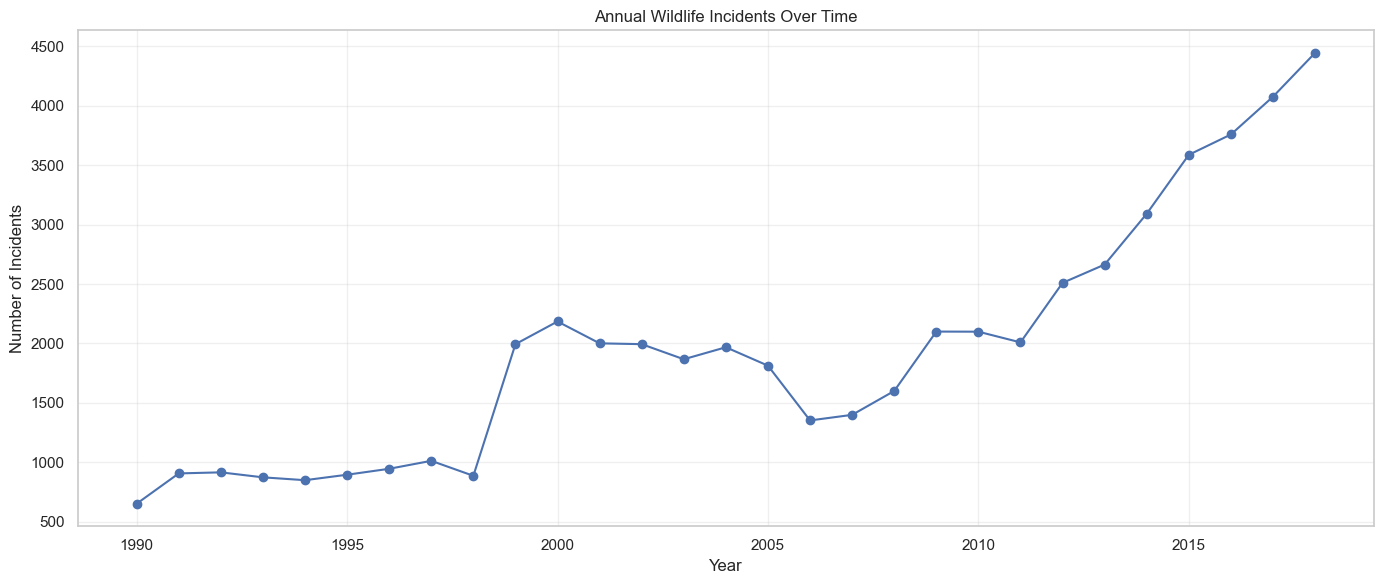

Years with the largest increases:
incident_year
1999    1108.0
2012     501.0
2009     500.0
2015     496.0
2014     428.0
dtype: float64

Years with the largest decreases:
incident_year
2006   -461.0
2001   -184.0
2005   -155.0
2003   -127.0
1998   -126.0
dtype: float64


In [216]:
import matplotlib.pyplot as plt

yearly_incidents = df.groupby('incident_year').size().sort_index()
yearly_change = yearly_incidents.diff()

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(yearly_incidents.index, yearly_incidents.values, marker='o')
ax.set_title('Annual Wildlife Incidents Over Time')
ax.set_xlabel('Year')
ax.set_ylabel('Number of Incidents')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Years with the largest increases:")
print(yearly_change.nlargest(5))

print("\nYears with the largest decreases:")
print(yearly_change.nsmallest(5))

### Interpretation
- Wildlife incidents generally increased between 1990 and 2018.
- From 1990 to 1998, annual incidents remained relatively low, at approximately 650–1,000.
- A sharp increase occurred in 1999, when incidents rose to approximately 2,000.
- Incidents fluctuated between 2000 and 2008, reaching a low point around 2006.
- From 2009 onward, incidents generally increased, with particularly strong growth after 2012.
- The highest number of incidents occurred in 2018, at approximately 4,400.
- **Conclusion:** The dataset shows a substantial long-term increase in reported wildlife incidents, although the increase alone does not establish its cause.

## Question 28: Which seasons have the highest and lowest numbers of wildlife incidents?

Wildlife incidents by season:
Spring    13213
Summer    17639
Autumn    19674
Winter     5923
Name: season, dtype: int64


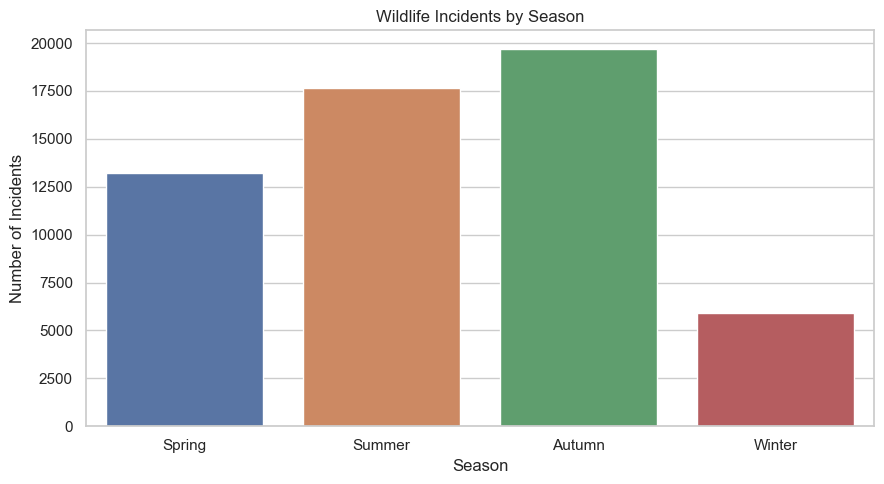

In [217]:
import matplotlib.pyplot as plt
import seaborn as sns

season_order = ['Spring', 'Summer', 'Autumn', 'Winter']

season_counts = (
    df['season']
    .value_counts()
    .reindex(season_order)
)

print("Wildlife incidents by season:")
print(season_counts)

plt.figure(figsize=(9, 5))
sns.barplot(x=season_counts.index, y=season_counts.values)
plt.title('Wildlife Incidents by Season')
plt.xlabel('Season')
plt.ylabel('Number of Incidents')
plt.tight_layout()
plt.show()

### Interpretation
- Autumn has the highest number of wildlife incidents, with approximately 19,700 incidents.
- Summer ranks second, with approximately 17,600 incidents.
- Spring records approximately 13,200 incidents.
- Winter has the lowest number of incidents, with approximately 5,900 incidents.
- **Conclusion:** Wildlife incidents are most frequent during autumn and summer and least frequent during winter.

## Question 29: Which years experienced the highest number of wildlife incidents for each time of day?

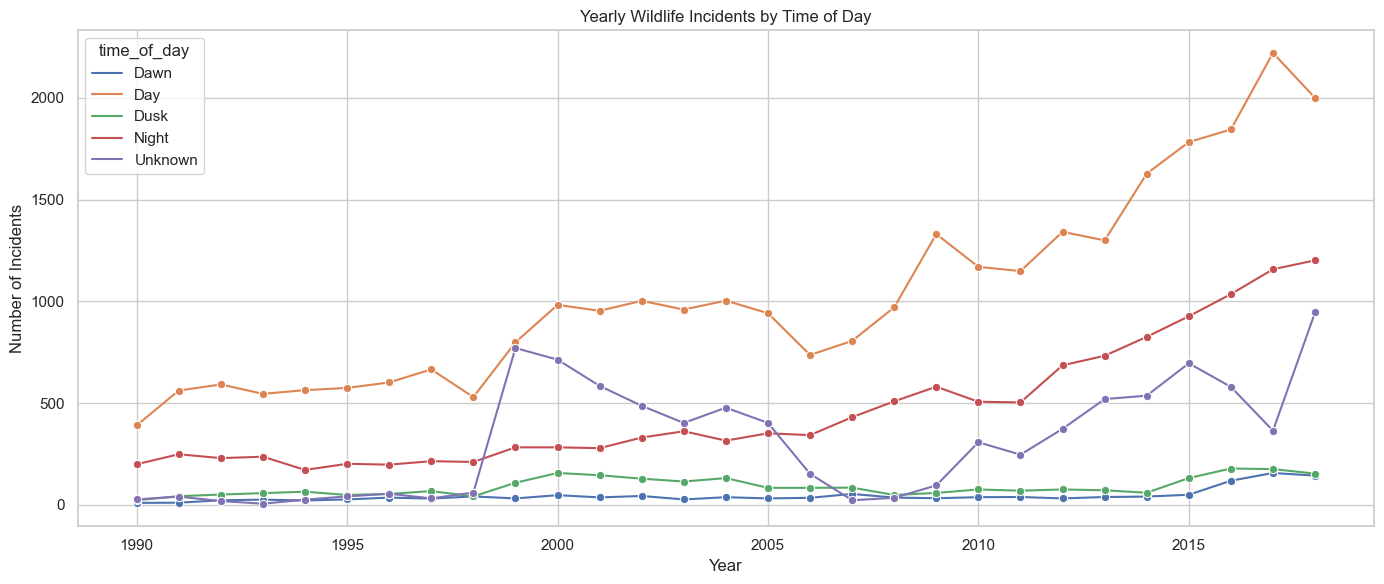

Year with the highest incidents for each time of day:
 incident_year time_of_day  incident_count
          2017        Dawn             157
          2017         Day            2221
          2016        Dusk             179
          2018       Night            1202
          2018     Unknown             946


In [218]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

year_time = (
    df.groupby(['incident_year', 'time_of_day'])
    .size()
    .reset_index(name='incident_count')
)

plt.figure(figsize=(14, 6))
sns.lineplot(
    data=year_time,
    x='incident_year',
    y='incident_count',
    hue='time_of_day',
    marker='o'
)

plt.title('Yearly Wildlife Incidents by Time of Day')
plt.xlabel('Year')
plt.ylabel('Number of Incidents')
plt.tight_layout()
plt.show()

peak_years = year_time.loc[
    year_time.groupby('time_of_day')['incident_count'].idxmax()
]

print("Year with the highest incidents for each time of day:")
print(peak_years.sort_values('time_of_day').to_string(index=False))

### Interpretation
- Daytime incidents show the strongest overall increase, reaching their highest level around 2017 at approximately 1,950 incidents.
- Nighttime incidents generally increased over the years, reaching approximately 1,150 incidents in 2018.
- Unknown-time incidents peaked around 2000 at approximately 1,350, declined afterward, and increased again in later years.
- Dawn and dusk incidents remained comparatively low throughout the period.
- **Conclusion:** Daytime has the highest number of wildlife incidents, while nighttime incidents also show a clear upward trend.

## Question 30: How does the seasonal distribution of incidents differ across time periods?

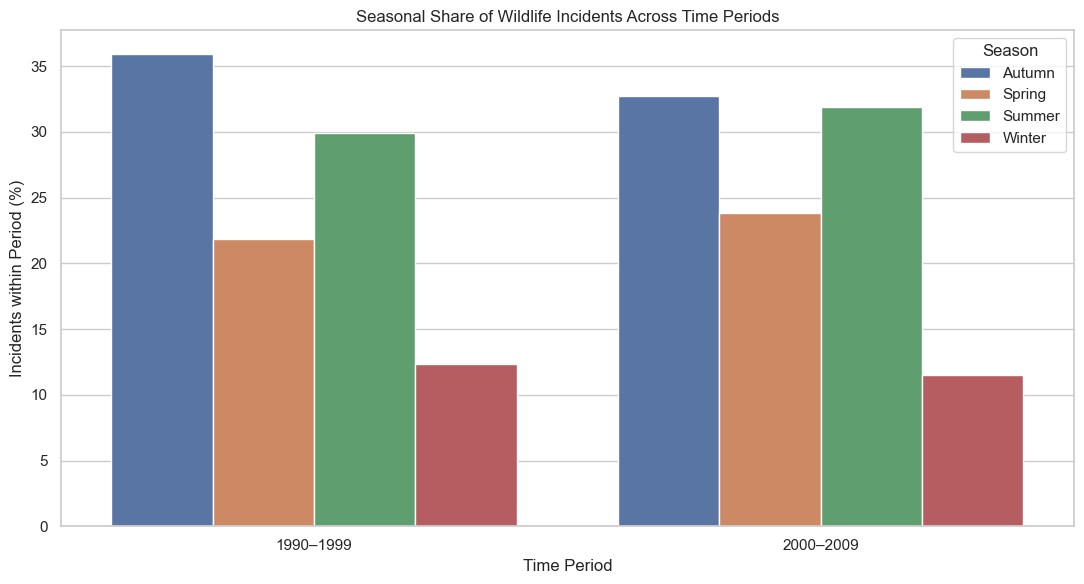

Seasonal percentage within each time period:
season      Autumn  Spring  Summer  Winter
year_group                                
1990–1999    35.93   21.84   29.92   12.31
2000–2009    32.75   23.81   31.91   11.53
2010–2018    35.83   23.70   31.28    9.18


In [219]:
# Compare each season's share of incidents within each engineered year group.
season_period = (
    df.groupby(['year_group', 'season'], observed=False)
      .size()
      .reset_index(name='incident_count')
)
season_period['period_total'] = season_period.groupby('year_group', observed=False)['incident_count'].transform('sum')
season_period['percentage'] = 100 * season_period['incident_count'] / season_period['period_total']

period_order = [x for x in ['Before 2000', '1990–1999', '2000–2009', '2010–2019'] if x in season_period['year_group'].astype(str).unique()]
plt.figure(figsize=(11, 6))
sns.barplot(
    data=season_period,
    x='year_group',
    y='percentage',
    hue='season',
    order=period_order if period_order else None
)
plt.title('Seasonal Share of Wildlife Incidents Across Time Periods')
plt.xlabel('Time Period')
plt.ylabel('Incidents within Period (%)')
plt.legend(title='Season')
plt.tight_layout()
plt.show()

print('Seasonal percentage within each time period:')
print(season_period.pivot(index='year_group', columns='season', values='percentage').round(2).to_string())

### Interpretation
- This chart compares the percentage of incidents attributed to each season within each time period, rather than comparing raw totals across periods of different sizes.
- Use the printed table to identify whether the seasonal mix is broadly stable or changes across time periods.
- A higher percentage indicates a larger share of that period's recorded incidents, not necessarily a higher wildlife-strike risk per flight.
- **Conclusion:** Interpret seasonal percentages alongside the annual trend and the dataset's reporting coverage; incident counts alone do not measure risk per flight.

# Executive Summary

This project explores recorded wildlife impacts on aviation using Python, Pandas, NumPy, Matplotlib, and Seaborn. It examines data quality, incident distributions, relationships among variables, seasonal patterns, and changes over time.

## Main findings

- The recorded incident counts vary by year, month, season, species category, flight phase, and time of day.
- Unknown bird categories account for a substantial share of the recorded species classifications.
- Most records are categorized as causing no damage, and the approach phase is prominent in the recorded incidents.
- Height and speed show a positive association in the numerical analysis; correlation alone does not establish causation.
- IQR screening is limited to continuous measurements such as height and speed. Discrete engine counts and HHMM clock times are assessed using appropriate frequency and validity checks.

## Data-quality and interpretation notes

- Counts represent records in the dataset, not incident risk per flight. Changes in air traffic volume, reporting practices, and data collection may affect observed trends.
- The repair-cost field is excluded from some analyses because it has a high proportion of missing values.
- Potential outliers are retained unless independent checks indicate invalid data.
- Confirm the units and documented valid ranges for height and speed before making domain-specific claims.
- Confirm that the month-to-season mapping is appropriate for the dataset's geographic context.

# Final Findings and Conclusions

## Key Findings

- **Annual trends:** Recorded incident counts generally increased over the period represented in the dataset. Interpret this alongside possible changes in flight volume and reporting.
- **Monthly and seasonal patterns:** The recorded counts differ by month and season; autumn has the highest count under the season mapping used in this notebook.
- **Species involvement:** Unknown bird-medium and unknown bird-small are among the most frequently recorded species categories.
- **Damage distribution:** Most records are categorized as causing no damage.
- **Flight phase:** The approach phase has the highest number of reported incidents in the analyzed records.
- **Time of day:** Daytime incidents are the most frequent among the time-of-day categories used in this analysis.
- **Numerical variables:** Height and speed show skewed distributions and potential extreme values. IQR flags are screening signals, not proof of data errors.
- **Correlation:** Height and speed show a positive correlation in the analyzed records; this does not imply a causal relationship.

## Conclusion

This EDA describes patterns in recorded wildlife incidents across time, seasons, species categories, flight phases, and numerical measurements. The results provide a useful descriptive overview, but they do not prove that a particular factor caused incidents or that the underlying risk per flight increased.

The notebook uses variable-appropriate checks: engine counts are treated as discrete values, HHMM clock times are validated by their hour/minute components, and IQR screening is applied to continuous measurements. Potential outliers are not automatically removed because extreme observations may be valid and analytically important.

Recommended next steps are to document the original dataset source and measurement units, verify the seasonal mapping, and—if suitable flight-volume data are available—compare incident rates per flight or movement rather than raw counts alone. The notebook can be reproduced by placing the source CSV file beside it and running the cells from top to bottom.